In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
population = pd.read_csv("population_district.csv")
income = pd.read_csv("hh_income_district.csv")
schools = pd.read_csv("schools_district.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [3]:
print("Population:", population.shape)
print("Household Income:", income.shape)
print("School Distribution:", schools.shape) 

Population: (451668, 7)
Household Income: (480, 5)
School Distribution: (4514, 6)


In [4]:
population.head() 

,state,district,date,sex,age,ethnicity,population
0,Johor,Batu Pahat,2020-01-01,both,overall,overall,495.3
1,Johor,Batu Pahat,2020-01-01,both,overall,bumi_malay,311.3
2,Johor,Batu Pahat,2020-01-01,both,overall,bumi_other,5.1
3,Johor,Batu Pahat,2020-01-01,both,overall,chinese,140.1
4,Johor,Batu Pahat,2020-01-01,both,overall,indian,6.9


In [5]:
population.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 451668 entries, 0 to 451667
Data columns (total 7 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   state       451668 non-null  object 
 1   district    451668 non-null  object 
 2   date        451668 non-null  object 
 3   sex         451668 non-null  object 
 4   age         451668 non-null  object 
 5   ethnicity   451668 non-null  object 
 6   population  451668 non-null  float64
dtypes: float64(1), object(6)
memory usage: 24.1+ MB


In [6]:
population.describe() 

,population
count,451668.000000
mean,4.138404
std,28.902320
min,0.000000
25%,0.000000
50%,0.200000
75%,1.500000
max,2382.000000


In [7]:
population.columns

Index(['state', 'district', 'date', 'sex', 'age', 'ethnicity', 'population'], dtype='object')

In [8]:
population.isnull().sum() 

state         0
district      0
date          0
sex           0
age           0
ethnicity     0
population    0
dtype: int64

In [9]:
print("Total Duplicate Records:", population.duplicated().sum()) 

Total Duplicate Records: 0


In [10]:
population['sex'].unique() 

array(['both', 'female', 'male'], dtype=object)

In [11]:
population['age'].unique() 

array(['overall', '0-4', '5-9', '10-14', '15-19', '20-24', '25-29',
       '30-34', '35-39', '40-44', '45-49', '50-54', '55-59', '60-64',
       '65-69', '70-74', '75-79', '80-84', '85+'], dtype=object)

In [12]:
population['ethnicity'].unique() 

array(['overall', 'bumi_malay', 'bumi_other', 'chinese', 'indian',
       'other_citizen', 'other_noncitizen'], dtype=object)

In [13]:
population['date'].unique() 

array(['2020-01-01', '2021-01-01', '2022-01-01', '2023-01-01',
       '2024-01-01', '2025-01-01', '2026-01-01'], dtype=object)

In [14]:
population['sex'].value_counts() 

sex
both      150556
female    150556
male      150556
Name: count, dtype: int64

In [15]:
population['age'].value_counts() 

age
overall    23772
0-4        23772
5-9        23772
10-14      23772
15-19      23772
20-24      23772
25-29      23772
30-34      23772
35-39      23772
40-44      23772
45-49      23772
50-54      23772
55-59      23772
60-64      23772
65-69      23772
70-74      23772
75-79      23772
80-84      23772
85+        23772
Name: count, dtype: int64

In [16]:
population['ethnicity'].value_counts() 

ethnicity
overall             64524
bumi_malay          64524
bumi_other          64524
chinese             64524
indian              64524
other_citizen       64524
other_noncitizen    64524
Name: count, dtype: int64

In [17]:
population['date'].value_counts()

date
2026-01-01    66234
2025-01-01    66234
2020-01-01    63840
2022-01-01    63840
2021-01-01    63840
2024-01-01    63840
2023-01-01    63840
Name: count, dtype: int64

In [18]:
print("Total States:", population['state'].nunique())

print("\nState List:")
print(sorted(population['state'].unique()))

Total States: 16

State List:
['Johor', 'Kedah', 'Kelantan', 'Melaka', 'Negeri Sembilan', 'Pahang', 'Perak', 'Perlis', 'Pulau Pinang', 'Sabah', 'Sarawak', 'Selangor', 'Terengganu', 'W.P. Kuala Lumpur', 'W.P. Labuan', 'W.P. Putrajaya']


In [19]:
print("Total Districts:", population['district'].nunique())

Total Districts: 166


In [20]:
population.groupby('date')['district'].nunique()

date
2020-01-01    160
2021-01-01    160
2022-01-01    160
2023-01-01    160
2024-01-01    160
2025-01-01    166
2026-01-01    166
Name: district, dtype: int64

In [21]:
population['date'] = pd.to_datetime(population['date'])

population.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 451668 entries, 0 to 451667
Data columns (total 7 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   state       451668 non-null  object        
 1   district    451668 non-null  object        
 2   date        451668 non-null  datetime64[ns]
 3   sex         451668 non-null  object        
 4   age         451668 non-null  object        
 5   ethnicity   451668 non-null  object        
 6   population  451668 non-null  float64       
dtypes: datetime64[ns](1), float64(1), object(5)
memory usage: 24.1+ MB


In [22]:
district_by_year = (
    population[['date', 'state', 'district']]
    .drop_duplicates()
    .groupby('date')
    .size()
)

print(district_by_year)

date
2020-01-01    160
2021-01-01    160
2022-01-01    160
2023-01-01    160
2024-01-01    160
2025-01-01    166
2026-01-01    166
dtype: int64


In [23]:
states_by_year = (
    population[['date', 'state']]
    .drop_duplicates()
    .groupby('date')
    .size()
)

print(states_by_year)

date
2020-01-01    16
2021-01-01    16
2022-01-01    16
2023-01-01    16
2024-01-01    16
2025-01-01    16
2026-01-01    16
dtype: int64


In [24]:
district_2024 = set(
    population[population['date'].dt.year == 2024]
    [['state', 'district']]
    .drop_duplicates()
    .itertuples(index=False, name=None)
)

district_2025 = set(
    population[population['date'].dt.year == 2025]
    [['state', 'district']]
    .drop_duplicates()
    .itertuples(index=False, name=None)
)

new_districts = district_2025 - district_2024

print("Additional district combinations in 2025:")

for state, district in sorted(new_districts):
    print(state, "-", district)

Additional district combinations in 2025:
Sabah - Membakut
Sarawak - Gedong
Sarawak - Lingga
Sarawak - Pantu
Sarawak - Sebuyau
Sarawak - Siburan


In [25]:
# Filter overall ethnicity
population_clean = population[
    population['ethnicity'] == 'overall'
].copy()

# Check the result
print("Original Dataset:", population.shape)
print("Cleaned Dataset:", population_clean.shape)

# Check ethnicity
print("\nEthnicity Categories:")
print(population_clean['ethnicity'].unique())

Original Dataset: (451668, 7)
Cleaned Dataset: (64524, 7)

Ethnicity Categories:
['overall']


In [26]:
print("Sex Categories:")
print(population_clean['sex'].value_counts())

print("\nAge Categories:")
print(population_clean['age'].value_counts())

Sex Categories:
sex
both      21508
female    21508
male      21508
Name: count, dtype: int64

Age Categories:
age
overall    3396
0-4        3396
5-9        3396
10-14      3396
15-19      3396
20-24      3396
25-29      3396
30-34      3396
35-39      3396
40-44      3396
45-49      3396
50-54      3396
55-59      3396
60-64      3396
65-69      3396
70-74      3396
75-79      3396
80-84      3396
85+        3396
Name: count, dtype: int64


In [27]:
print(
    population_clean.groupby(
        population_clean['date'].dt.year
    ).size()
)


date
2020    9120
2021    9120
2022    9120
2023    9120
2024    9120
2025    9462
2026    9462
dtype: int64


In [28]:
# Filter age groups (exclude overall)
population_age = population_clean[
    population_clean['age'] != 'overall'
].copy()

# Compare both with male + female
sex_check = population_age.pivot_table(
    index=['date', 'state', 'district', 'age'],
    columns='sex',
    values='population',
    aggfunc='sum'
).reset_index()

# Calculate difference
sex_check['difference'] = (
    sex_check['both'] -
    (sex_check['male'] + sex_check['female'])
)

print("Total comparisons:", len(sex_check))

print(
    "Mismatched records:",
    (sex_check['difference'].abs() > 0.01).sum()
)

print("\nSample comparison:")
print(sex_check.head())


Total comparisons: 20376
Mismatched records: 5076

Sample comparison:
sex       date  state    district    age  both  female  male  difference
0   2020-01-01  Johor  Batu Pahat    0-4  30.3    15.3  15.0         0.0
1   2020-01-01  Johor  Batu Pahat  10-14  40.0    19.4  20.6         0.0
2   2020-01-01  Johor  Batu Pahat  15-19  45.0    21.5  23.5         0.0
3   2020-01-01  Johor  Batu Pahat  20-24  49.0    21.5  27.5         0.0
4   2020-01-01  Johor  Batu Pahat  25-29  45.3    19.8  25.6        -0.1


In [29]:

# Calculate absolute difference
sex_check['abs_difference'] = (
    sex_check['difference'].abs()
)

# Check difference distribution
print("Difference Distribution:")

print(
    sex_check['difference']
    .round(1)
    .value_counts()
    .sort_index()
)

# Check mismatches above 0.1
print("\nMismatches above 0.1:")

print(
    (sex_check['abs_difference'] > 0.1).sum()
)

# Check maximum difference
print("\nMaximum Absolute Difference:")

print(sex_check['abs_difference'].max())


Difference Distribution:
difference
-0.1     2621
 0.0    15300
 0.1     2455
Name: count, dtype: int64

Mismatches above 0.1:
2348

Maximum Absolute Difference:
0.10000000000002274


In [30]:
# Round differences to 1 decimal place
sex_check['rounded_difference'] = (
    sex_check['difference'].round(1)
)

# Count differences after rounding
print("Final Validation:")

print(
    "Records with difference above 0.1:",
    (sex_check['rounded_difference'].abs() > 0.1).sum()
)

print(
    "Records within 0.1 tolerance:",
    (sex_check['rounded_difference'].abs() <= 0.1).sum()
)

print("\nRounded Difference Distribution:")
print(sex_check['rounded_difference'].value_counts().sort_index())

Final Validation:
Records with difference above 0.1: 0
Records within 0.1 tolerance: 20376

Rounded Difference Distribution:
rounded_difference
-0.1     2621
 0.0    15300
 0.1     2455
Name: count, dtype: int64


In [31]:
# Prepare population data for visualization
population_viz = population_clean[
    (population_clean['sex'].isin(['male', 'female'])) &
    (population_clean['age'] != 'overall') &
    (population_clean['date'].dt.year == 2026)
].copy()

# Display dataset information
print("Visualization Dataset Shape:", population_viz.shape)

print("\nSex Categories:")
print(population_viz['sex'].unique())

print("\nAge Categories:")
print(population_viz['age'].unique())

# Preview data
population_viz.head()

Visualization Dataset Shape: (5976, 7)

Sex Categories:
['male' 'female']

Age Categories:
['0-4' '5-9' '10-14' '15-19' '20-24' '25-29' '30-34' '35-39' '40-44'
 '45-49' '50-54' '55-59' '60-64' '65-69' '70-74' '75-79' '80-84' '85+']


,state,district,date,sex,age,ethnicity,population
385454,Johor,Batu Pahat,2026-01-01,male,0-4,overall,15.3
385455,Johor,Batu Pahat,2026-01-01,male,5-9,overall,14.8
385456,Johor,Batu Pahat,2026-01-01,male,10-14,overall,18.0
385457,Johor,Batu Pahat,2026-01-01,male,15-19,overall,21.7
385458,Johor,Batu Pahat,2026-01-01,male,20-24,overall,27.4


In [32]:
print("Total Records:", len(population_viz))

print("\nRecords by Sex:")
print(population_viz['sex'].value_counts())

print("\nMissing Values:")
print(population_viz.isnull().sum())

print("\nDuplicate Records:")
print(population_viz.duplicated().sum())

Total Records: 5976

Records by Sex:
sex
male      2988
female    2988
Name: count, dtype: int64

Missing Values:
state         0
district      0
date          0
sex           0
age           0
ethnicity     0
population    0
dtype: int64

Duplicate Records:
0


In [33]:
# Define age group order
age_order = [
    '0-4', '5-9', '10-14', '15-19',
    '20-24', '25-29', '30-34', '35-39',
    '40-44', '45-49', '50-54', '55-59',
    '60-64', '65-69', '70-74', '75-79',
    '80-84', '85+'
]

# Aggregate population by age and sex
population_by_age_sex = (
    population_viz
    .groupby(['age', 'sex'])['population']
    .sum()
    .reset_index()
)

# Arrange age groups in correct order
population_by_age_sex['age'] = pd.Categorical(
    population_by_age_sex['age'],
    categories=age_order,
    ordered=True
)

population_by_age_sex = population_by_age_sex.sort_values('age')

# Display result
population_by_age_sex


,age,sex,population
0,0-4,female,1046.7
1,0-4,male,1119.4
19,5-9,male,1270.4
18,5-9,female,1213.4
2,10-14,female,1278.6
3,10-14,male,1364.1
4,15-19,female,1285.2
5,15-19,male,1414.7
6,20-24,female,1406.0
7,20-24,male,1713.8


In [34]:
population_pyramid = population_by_age_sex.pivot(
    index='age',
    columns='sex',
    values='population'
)

population_pyramid


sex,female,male
age,,
0-4,1046.7,1119.4
5-9,1213.4,1270.4
10-14,1278.6,1364.1
15-19,1285.2,1414.7
20-24,1406.0,1713.8
25-29,1376.5,1755.1
30-34,1283.6,1587.3
35-39,1322.8,1502.9
40-44,1291.8,1415.9


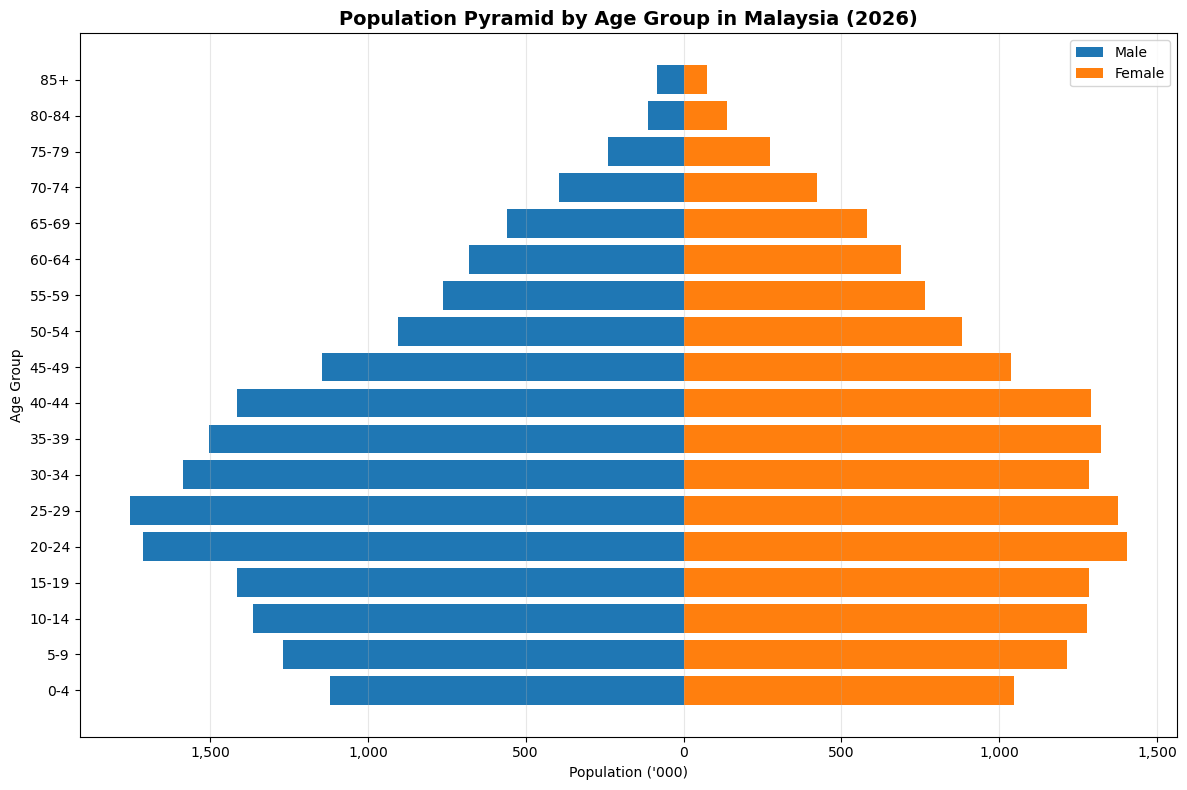

In [36]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Prepare data
pyramid_plot = population_pyramid.copy()

# Make male values negative
pyramid_plot['male'] = -pyramid_plot['male']

# Create figure
fig, ax = plt.subplots(figsize=(12, 8))

# Plot male and female bars
ax.barh(
    pyramid_plot.index,
    pyramid_plot['male'],
    label='Male'
)

ax.barh(
    pyramid_plot.index,
    pyramid_plot['female'],
    label='Female'
)

# Format x-axis to show positive values
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'{abs(x):,.0f}')
)

# Labels and title
ax.set_title(
    'Population Pyramid by Age Group in Malaysia (2026)',
    fontsize=14,
    fontweight='bold'
)

ax.set_xlabel("Population ('000)")
ax.set_ylabel('Age Group')

# Reverse age order
# ax.invert_yaxis()

# Add legend and grid
ax.legend()
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()


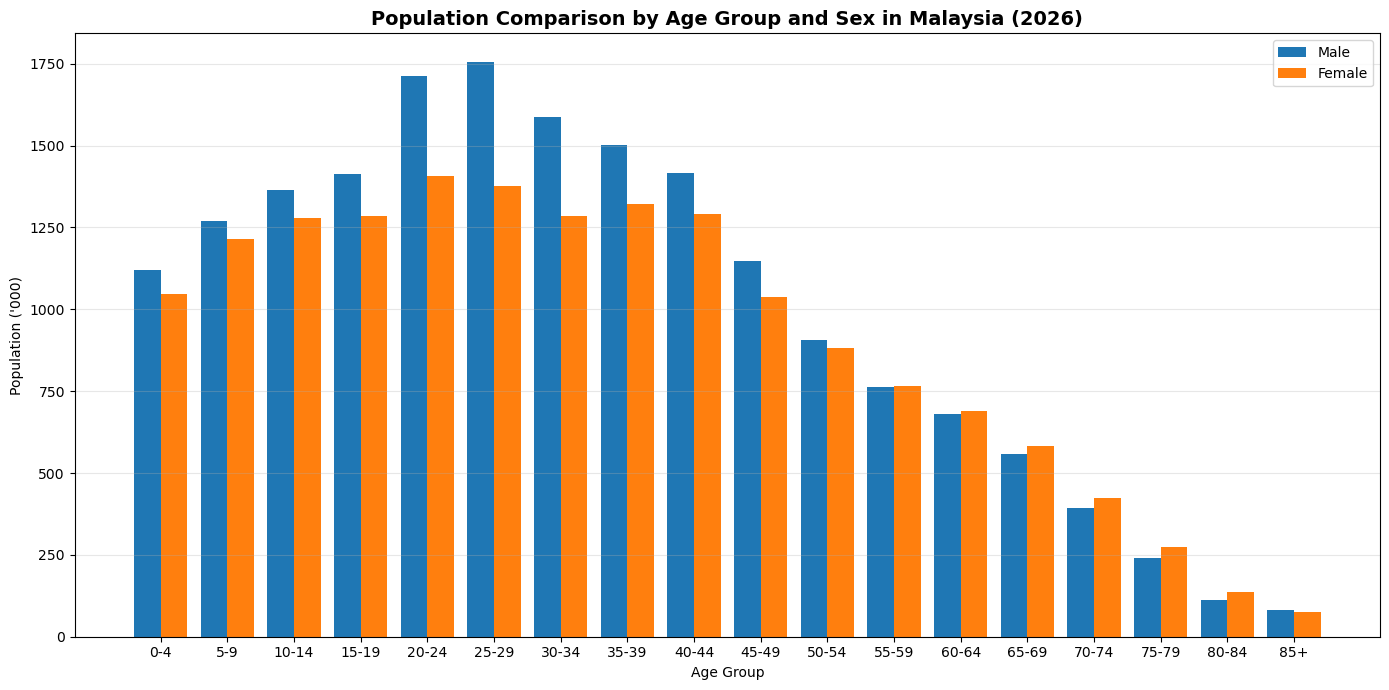

In [37]:
# Create Grouped Bar Chart
fig, ax = plt.subplots(figsize=(14, 7))

x = np.arange(len(population_pyramid.index))
width = 0.4

# Plot male and female bars
ax.bar(
    x - width/2,
    population_pyramid['male'],
    width,
    label='Male'
)

ax.bar(
    x + width/2,
    population_pyramid['female'],
    width,
    label='Female'
)

# Set chart labels
ax.set_title(
    'Population Comparison by Age Group and Sex in Malaysia (2026)',
    fontsize=14,
    fontweight='bold'
)

ax.set_xlabel('Age Group')
ax.set_ylabel("Population ('000)")

ax.set_xticks(x)
ax.set_xticklabels(population_pyramid.index)

ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


In [38]:
# Filter population data for heatmap
population_heatmap = population_clean[
    (population_clean['sex'] == 'both') &
    (population_clean['age'] != 'overall') &
    (population_clean['date'].dt.year == 2026)
].copy()

# Aggregate population by state and age
heatmap_data = population_heatmap.pivot_table(
    index='state',
    columns='age',
    values='population',
    aggfunc='sum'
)

# Arrange age groups in correct order
heatmap_data = heatmap_data[age_order]

# Display dataset
print("Heatmap Dataset Shape:", heatmap_data.shape)

heatmap_data


Heatmap Dataset Shape: (16, 18)


age,0-4,5-9,10-14,15-19,20-24,25-29,30-34,35-39,40-44,45-49,50-54,55-59,60-64,65-69,70-74,75-79,80-84,85+
state,,,,,,,,,,,,,,,,,,
Johor,248.8,296.2,318.9,349.7,396.7,409.9,350.7,328.3,310.5,260.5,227.0,205.3,179.4,153.4,87.4,51.2,28.6,21.5
Kedah,159.5,177.1,183.3,177.1,192.1,222.9,197.1,156.5,131.7,114.4,108.9,103.6,95.8,83.8,59.6,38.6,19.5,16.2
Kelantan,164.8,173.1,183.5,182.1,202.5,182.6,137.1,117.1,108.9,87.7,81.6,78.5,76.1,62.8,42.7,26.3,12.3,6.2
Melaka,63.0,78.8,85.8,70.0,103.6,100.8,120.1,77.7,73.7,79.2,48.7,38.3,38.1,32.5,24.6,14.0,6.1,2.7
Negeri Sembilan,76.5,85.3,116.9,98.3,107.8,107.7,100.2,105.0,98.8,75.0,61.5,51.0,57.0,44.6,32.6,19.7,8.2,3.0
Pahang,110.8,131.1,139.7,146.4,167.3,141.2,126.7,130.7,133.8,117.5,87.0,68.1,60.0,48.2,32.9,24.2,10.9,10.2
Perak,141.1,164.5,204.4,205.0,238.2,241.7,197.0,182.5,188.6,161.4,131.0,119.2,124.6,106.4,81.5,53.7,24.8,13.1
Perlis,18.3,19.2,19.5,18.8,36.4,34.0,23.0,19.1,20.4,24.5,14.8,11.5,11.7,9.9,8.0,4.9,2.3,1.1
Pulau Pinang,97.6,113.8,115.0,116.2,153.3,173.6,167.1,148.3,145.3,118.0,110.0,102.3,87.7,73.7,49.9,25.3,9.6,1.7


In [39]:
print("Total States:", heatmap_data.shape[0])
print("Total Age Groups:", heatmap_data.shape[1])

print("\nMissing Values:")
print(heatmap_data.isnull().sum().sum())


Total States: 16
Total Age Groups: 18

Missing Values:
0


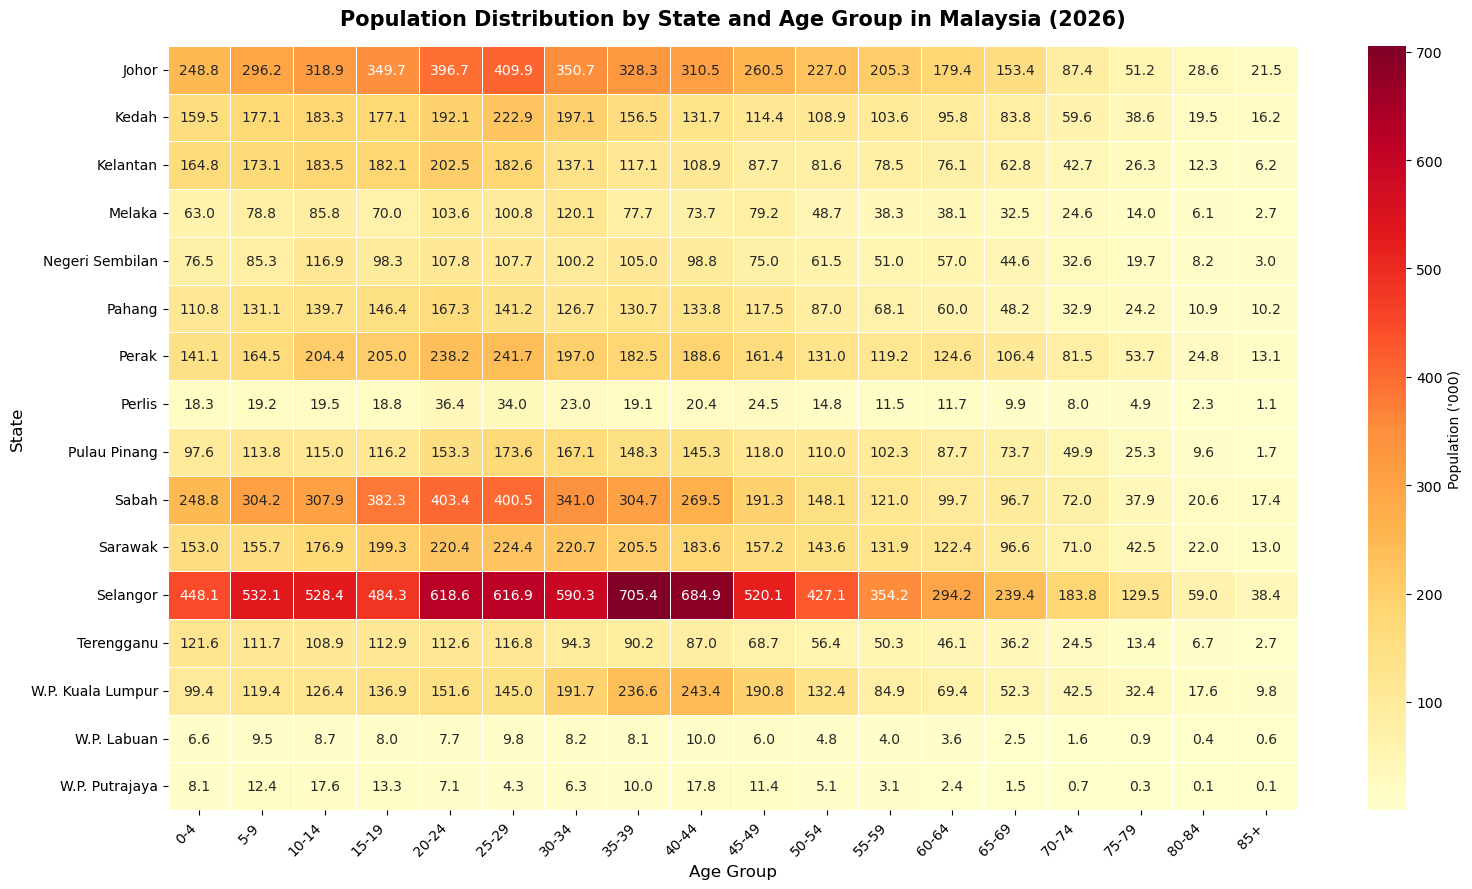

In [40]:
# Create Heatmap
plt.figure(figsize=(16, 9))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=0.5,
    cbar_kws={
        'label': "Population ('000)"
    }
)

# Set title and labels
plt.title(
    'Population Distribution by State and Age Group in Malaysia (2026)',
    fontsize=15,
    fontweight='bold',
    pad=15
)

plt.xlabel('Age Group', fontsize=12)
plt.ylabel('State', fontsize=12)

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [41]:
# Find highest population
max_value = heatmap_data.max().max()

max_location = heatmap_data.stack().idxmax()

# Find lowest population
min_value = heatmap_data.min().min()

min_location = heatmap_data.stack().idxmin()

print("Highest Population:")
print("State:", max_location[0])
print("Age Group:", max_location[1])
print("Population:", max_value, "'000")

print("\nLowest Population:")
print("State:", min_location[0])
print("Age Group:", min_location[1])
print("Population:", min_value, "'000")

Highest Population:
State: Selangor
Age Group: 35-39
Population: 705.4 '000

Lowest Population:
State: W.P. Putrajaya
Age Group: 80-84
Population: 0.1 '000


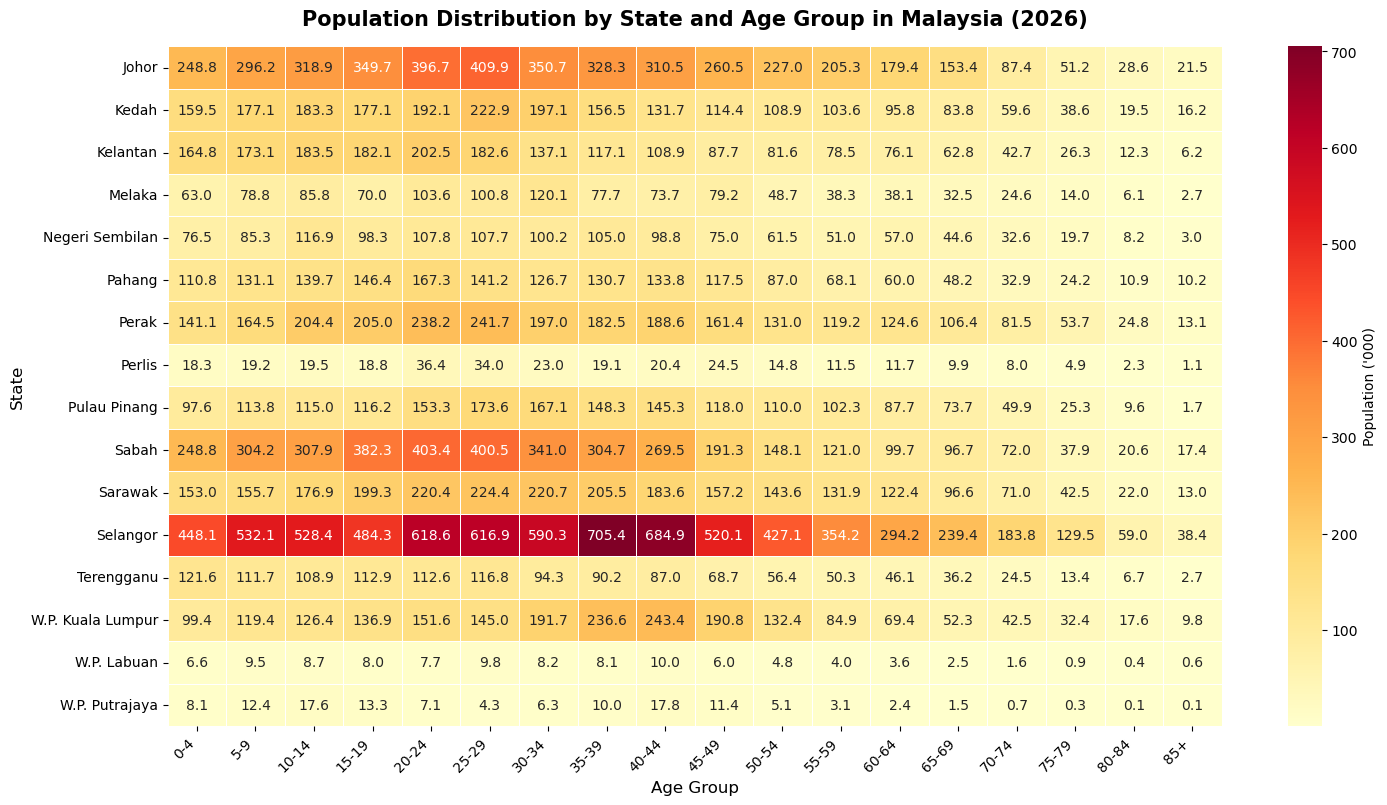

In [42]:
fig, ax = plt.subplots(figsize=(17, 10))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=0.5,
    cbar_kws={'label': "Population ('000)"},
    ax=ax
)

ax.set_title(
    'Population Distribution by State and Age Group in Malaysia (2026)',
    fontsize=15,
    fontweight='bold',
    pad=15
)

ax.set_xlabel('Age Group', fontsize=12)
ax.set_ylabel('State', fontsize=12)

ax.set_xticklabels(
    age_order,
    rotation=45,
    ha='right'
)

ax.set_yticklabels(
    heatmap_data.index,
    rotation=0
)

plt.subplots_adjust(bottom=0.20)
plt.show()

In [43]:
income.head()

,state,district,date,income_mean,income_median
0,Johor,Batu Pahat,2019-01-01,7392,6504
1,Johor,Batu Pahat,2022-01-01,7419,6347
2,Johor,Batu Pahat,2024-01-01,9006,7555
3,Johor,Johor Bahru,2019-01-01,9315,7342
4,Johor,Johor Bahru,2022-01-01,9869,8232


In [44]:
income.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   state          480 non-null    object
 1   district       480 non-null    object
 2   date           480 non-null    object
 3   income_mean    480 non-null    int64 
 4   income_median  480 non-null    int64 
dtypes: int64(2), object(3)
memory usage: 18.9+ KB


In [45]:
income.describe()

,income_mean,income_median
count,480.000000,480.000000
mean,5968.975000,4767.635417
std,2059.108752,1710.420818
min,2758.000000,1999.000000
25%,4707.000000,3636.000000
50%,5412.000000,4324.500000
75%,6702.500000,5570.750000
max,15906.000000,12608.000000


In [46]:
income.columns

Index(['state', 'district', 'date', 'income_mean', 'income_median'], dtype='object')

In [47]:
income.isnull().sum()


state            0
district         0
date             0
income_mean      0
income_median    0
dtype: int64

In [48]:
print("Total Duplicate Records:", income.duplicated().sum())


Total Duplicate Records: 0


In [49]:

print("Total States:", income['state'].nunique())

print("\nState List:")
print(sorted(income['state'].unique()))


Total States: 16

State List:
['Johor', 'Kedah', 'Kelantan', 'Melaka', 'Negeri Sembilan', 'Pahang', 'Perak', 'Perlis', 'Pulau Pinang', 'Sabah', 'Sarawak', 'Selangor', 'Terengganu', 'W.P. Kuala Lumpur', 'W.P. Labuan', 'W.P. Putrajaya']


In [50]:

print("Available Dates:")
print(sorted(income['date'].unique()))


Available Dates:
['2019-01-01', '2022-01-01', '2024-01-01']


In [51]:

print("Total Districts:", income['district'].nunique())


Total Districts: 172


In [52]:

income.groupby('date').size()


date
2019-01-01    158
2022-01-01    160
2024-01-01    162
dtype: int64

In [53]:

# Convert date column
income['date'] = pd.to_datetime(income['date'])

# Check data information
income.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   state          480 non-null    object        
 1   district       480 non-null    object        
 2   date           480 non-null    datetime64[ns]
 3   income_mean    480 non-null    int64         
 4   income_median  480 non-null    int64         
dtypes: datetime64[ns](1), int64(2), object(2)
memory usage: 18.9+ KB


In [54]:

district_by_year = (
    income[['date', 'state', 'district']]
    .drop_duplicates()
    .groupby('date')
    .size()
)

print("District Records by Year:")
print(district_by_year)


District Records by Year:
date
2019-01-01    158
2022-01-01    160
2024-01-01    162
dtype: int64


In [55]:

duplicate_districts = income.duplicated(
    subset=['date', 'state', 'district']
).sum()

print("Duplicate State-District-Year Records:",
      duplicate_districts)


Duplicate State-District-Year Records: 0


In [56]:
states_by_year = (
    income[['date', 'state']]
    .drop_duplicates()
    .groupby('date')
    .size()
)

print("State Coverage by Year:")
print(states_by_year)


State Coverage by Year:
date
2019-01-01    16
2022-01-01    16
2024-01-01    12
dtype: int64


In [57]:
# Get all states in the dataset
all_states = set(income['state'].unique())

# Get states available in 2024
states_2024 = set(
    income[income['date'].dt.year == 2024]['state'].unique()
)

# Identify missing states
missing_states_2024 = all_states - states_2024

print("States Available in 2024:", len(states_2024))

print("\nMissing States in 2024:")
for state in sorted(missing_states_2024):
    print(state)


States Available in 2024: 12

Missing States in 2024:
Perlis
W.P. Kuala Lumpur
W.P. Labuan
W.P. Putrajaya


In [58]:
district_coverage = (
    income.groupby(['date', 'state'])['district']
    .nunique()
    .unstack()
)

district_coverage


state,Johor,Kedah,Kelantan,Melaka,Negeri Sembilan,Pahang,Perak,Perlis,Pulau Pinang,Sabah,Sarawak,Selangor,Terengganu,W.P. Kuala Lumpur,W.P. Labuan,W.P. Putrajaya
date,,,,,,,,,,,,,,,,
2019-01-01,10.0,12.0,11.0,3.0,7.0,11.0,12.0,1.0,5.0,26.0,40.0,9.0,8.0,1.0,1.0,1.0
2022-01-01,10.0,12.0,11.0,3.0,7.0,11.0,13.0,1.0,5.0,27.0,40.0,9.0,8.0,1.0,1.0,1.0
2024-01-01,10.0,12.0,11.0,3.0,7.0,11.0,13.0,NaN,5.0,28.0,45.0,9.0,8.0,NaN,NaN,NaN


In [59]:
all_states = set(income['state'].unique())

states_2024 = set(
    income[income['date'].dt.year == 2024]['state'].unique()
)

missing_states_2024 = all_states - states_2024

print("Missing States in 2024:")
print(sorted(missing_states_2024))

print("\nTotal Missing States:",
      len(missing_states_2024))


Missing States in 2024:
['Perlis', 'W.P. Kuala Lumpur', 'W.P. Labuan', 'W.P. Putrajaya']

Total Missing States: 4


In [60]:
# Aggregate income by state and year
income_state_year = (
    income.groupby(['state', 'date'])
    .agg(
        avg_district_income=('income_mean', 'mean'),
        avg_district_median=('income_median', 'mean'),
        total_districts=('district', 'nunique')
    )
    .reset_index()
)

# Round income values to 2 decimal places
income_state_year['avg_district_income'] = (
    income_state_year['avg_district_income'].round(2)
)

income_state_year['avg_district_median'] = (
    income_state_year['avg_district_median'].round(2)
)

# Display result
income_state_year.head(10)


,state,date,avg_district_income,avg_district_median,total_districts
0,Johor,2019-01-01,7058.70,5839.00,10
1,Johor,2022-01-01,7403.70,6019.50,10
2,Johor,2024-01-01,8129.70,6855.90,10
3,Kedah,2019-01-01,5255.75,4243.42,12
4,Kedah,2022-01-01,5281.92,4281.33,12
5,Kedah,2024-01-01,5547.50,4692.58,12
6,Kelantan,2019-01-01,4419.73,3353.09,11
7,Kelantan,2022-01-01,4443.82,3338.73,11
8,Kelantan,2024-01-01,4765.45,3846.91,11
9,Melaka,2019-01-01,7496.67,5932.33,3


In [61]:
print("Prepared Dataset Shape:", income_state_year.shape)

print("\nMissing Values:")
print(income_state_year.isnull().sum())

print("\nAvailable Years:")
print(sorted(income_state_year['date'].dt.year.unique()))

print("\nPrepared Dataset:")
display(income_state_year.head(10))


Prepared Dataset Shape: (44, 5)

Missing Values:
state                  0
date                   0
avg_district_income    0
avg_district_median    0
total_districts        0
dtype: int64

Available Years:
[np.int32(2019), np.int32(2022), np.int32(2024)]

Prepared Dataset:


,state,date,avg_district_income,avg_district_median,total_districts
0,Johor,2019-01-01,7058.70,5839.00,10
1,Johor,2022-01-01,7403.70,6019.50,10
2,Johor,2024-01-01,8129.70,6855.90,10
3,Kedah,2019-01-01,5255.75,4243.42,12
4,Kedah,2022-01-01,5281.92,4281.33,12
5,Kedah,2024-01-01,5547.50,4692.58,12
6,Kelantan,2019-01-01,4419.73,3353.09,11
7,Kelantan,2022-01-01,4443.82,3338.73,11
8,Kelantan,2024-01-01,4765.45,3846.91,11
9,Melaka,2019-01-01,7496.67,5932.33,3


In [62]:
# Check duplicate records
print(
    "Duplicate State-Year Records:",
    income_state_year.duplicated(
        subset=['state', 'date']
    ).sum()
)

# Check records by year
print("\nRecords by Year:")
print(
    income_state_year.groupby(
        income_state_year['date'].dt.year
    ).size()
)

# Display all prepared records
display(income_state_year)


Duplicate State-Year Records: 0

Records by Year:
date
2019    16
2022    16
2024    12
dtype: int64


,state,date,avg_district_income,avg_district_median,total_districts
0,Johor,2019-01-01,7058.70,5839.00,10
1,Johor,2022-01-01,7403.70,6019.50,10
2,Johor,2024-01-01,8129.70,6855.90,10
3,Kedah,2019-01-01,5255.75,4243.42,12
4,Kedah,2022-01-01,5281.92,4281.33,12
5,Kedah,2024-01-01,5547.50,4692.58,12
6,Kelantan,2019-01-01,4419.73,3353.09,11
7,Kelantan,2022-01-01,4443.82,3338.73,11
8,Kelantan,2024-01-01,4765.45,3846.91,11
9,Melaka,2019-01-01,7496.67,5932.33,3


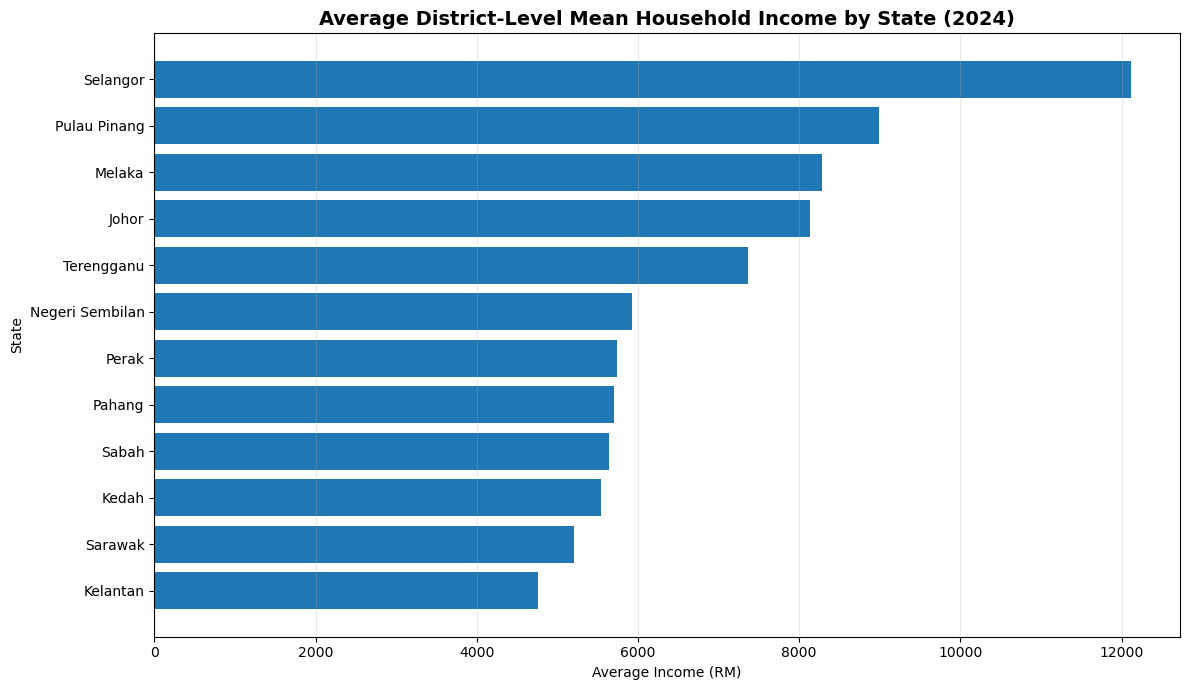

In [63]:
# Filter data for 2024
income_2024 = income_state_year[
    income_state_year['date'].dt.year == 2024
].copy()

# Sort income from highest to lowest
income_2024 = income_2024.sort_values(
    by='avg_district_income',
    ascending=True
)

# Create horizontal bar chart
plt.figure(figsize=(12, 7))

plt.barh(
    income_2024['state'],
    income_2024['avg_district_income']
)

# Add title and labels
plt.title(
    'Average District-Level Mean Household Income by State (2024)',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Average Income (RM)')
plt.ylabel('State')

plt.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()


In [64]:
# Identify states with records in all 3 years
state_year_count = (
    income_state_year.groupby('state')['date']
    .nunique()
)

complete_states = state_year_count[
    state_year_count == 3
].index.tolist()

# Filter complete records
income_trend = income_state_year[
    income_state_year['state'].isin(complete_states)
].copy()

# Create pivot table
income_trend_pivot = income_trend.pivot(
    index='date',
    columns='state',
    values='avg_district_income'
)

print("States with complete records:",
      len(complete_states))

print("\nTrend Dataset Shape:",
      income_trend_pivot.shape)

income_trend_pivot


States with complete records: 12

Trend Dataset Shape: (3, 12)


state,Johor,Kedah,Kelantan,Melaka,Negeri Sembilan,Pahang,Perak,Pulau Pinang,Sabah,Sarawak,Selangor,Terengganu
date,,,,,,,,,,,,
2019-01-01,7058.7,5255.75,4419.73,7496.67,5761.86,5184.00,5392.58,7620.0,5069.15,4625.08,9560.89,6558.25
2022-01-01,7403.7,5281.92,4443.82,7657.67,5485.29,5306.64,5424.15,8167.8,5368.63,4925.40,11087.44,6983.50
2024-01-01,8129.7,5547.50,4765.45,8280.67,5920.29,5704.55,5745.69,8994.4,5643.18,5204.78,12117.78,7370.62


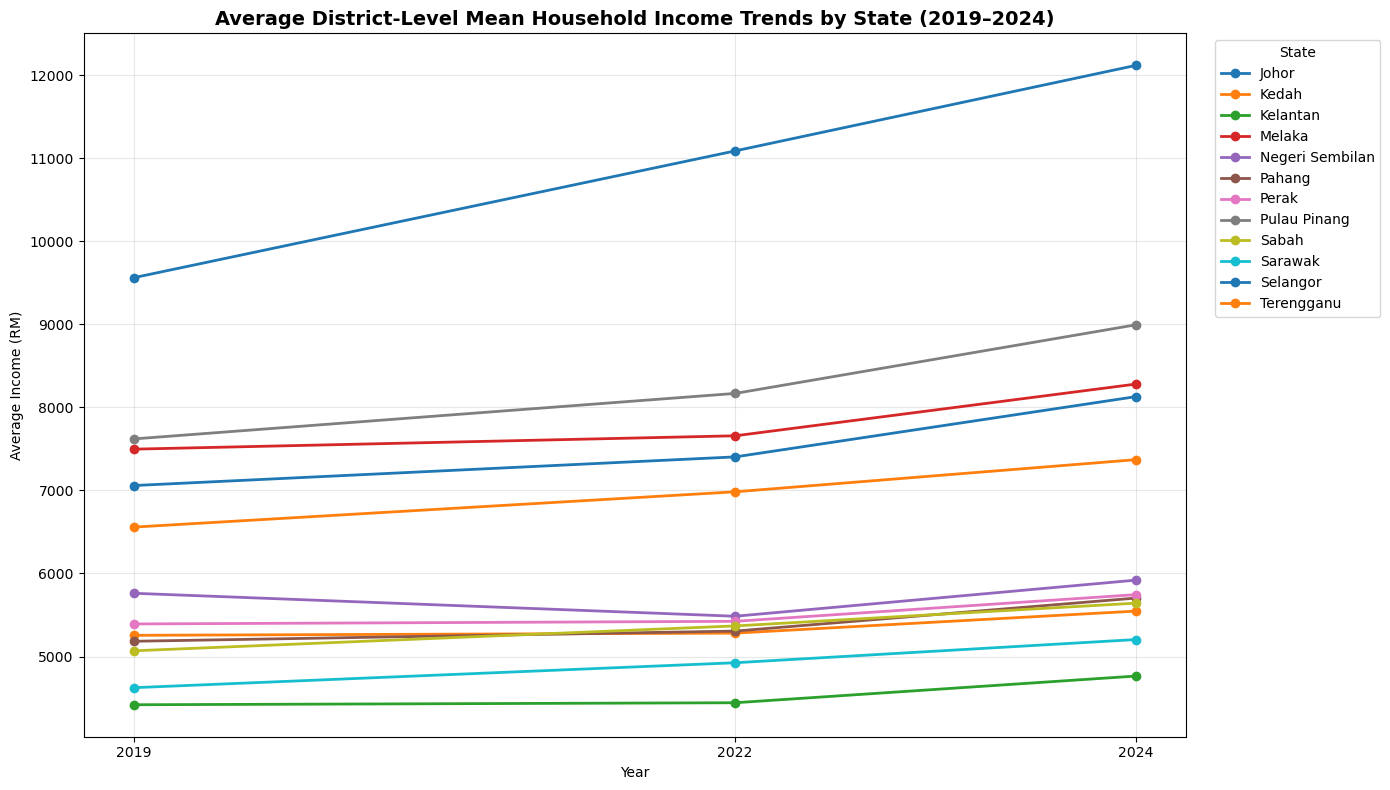

In [65]:
# Create line chart
plt.figure(figsize=(14, 8))

for state in income_trend_pivot.columns:
    plt.plot(
        income_trend_pivot.index.year,
        income_trend_pivot[state],
        marker='o',
        linewidth=2,
        label=state
    )

# Chart title and labels
plt.title(
    'Average District-Level Mean Household Income Trends by State (2019–2024)',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Year')
plt.ylabel('Average Income (RM)')

plt.xticks([2019, 2022, 2024])

plt.legend(
    title='State',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


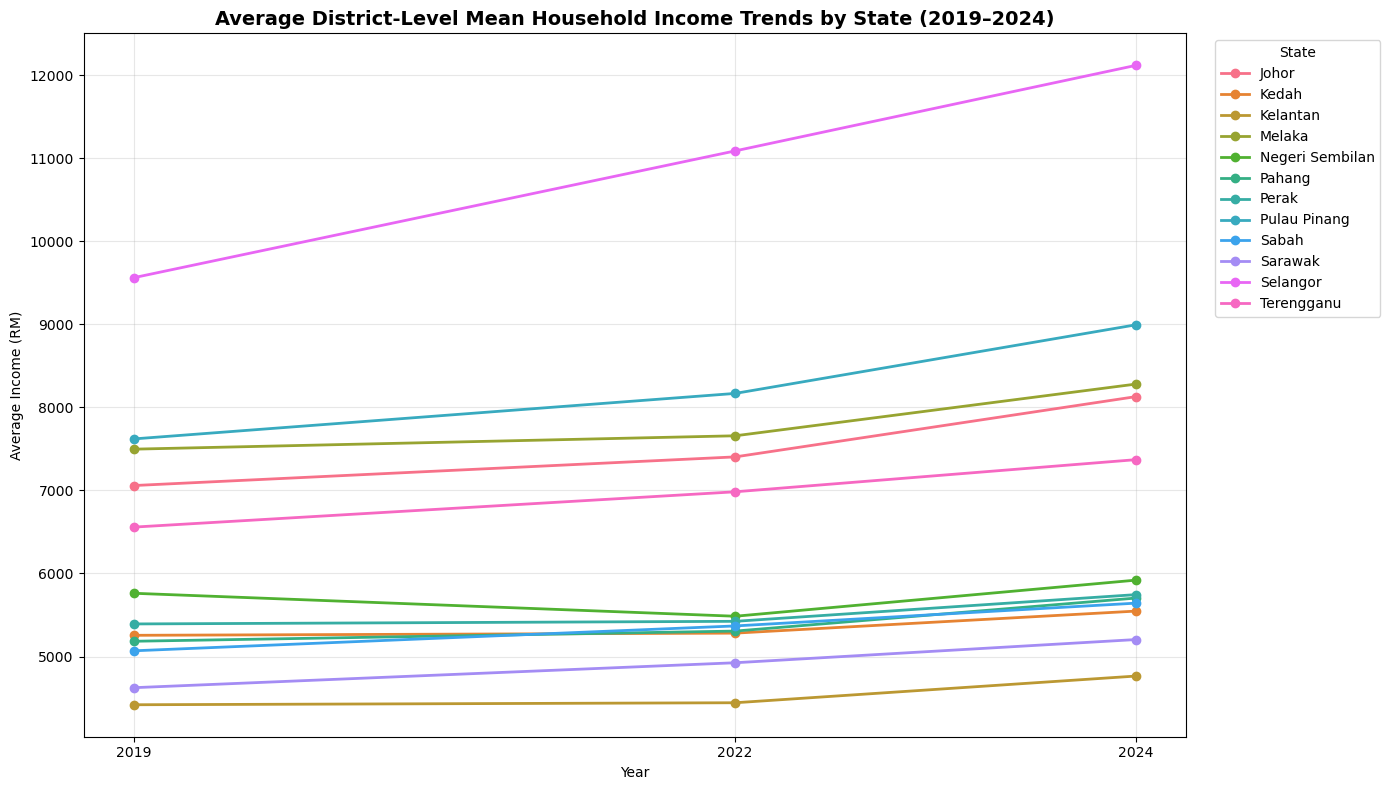

In [66]:
# Generate distinct colours for each state
colors = sns.color_palette(
    "husl",
    n_colors=len(income_trend_pivot.columns)
)

# Create line chart
fig, ax = plt.subplots(figsize=(14, 8))

for state, color in zip(
    income_trend_pivot.columns, colors
):
    ax.plot(
        income_trend_pivot.index.year,
        income_trend_pivot[state],
        marker='o',
        linewidth=2,
        markersize=6,
        color=color,
        label=state
    )

ax.set_title(
    'Average District-Level Mean Household Income Trends by State (2019–2024)',
    fontsize=14,
    fontweight='bold'
)

ax.set_xlabel('Year')
ax.set_ylabel('Average Income (RM)')

ax.set_xticks([2019, 2022, 2024])

ax.legend(
    title='State',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [67]:
# Filter data for 2024
income_compare = income_state_year[
    income_state_year['date'].dt.year == 2024
].copy()

# Sort by average district income
income_compare = income_compare.sort_values(
    by='avg_district_income',
    ascending=False
)

# Display prepared dataset
print("Grouped Bar Chart Dataset:",
      income_compare.shape)

display(
    income_compare[
        ['state', 'avg_district_income',
         'avg_district_median']
    ]
)


Grouped Bar Chart Dataset: (12, 5)


,state,avg_district_income,avg_district_median
34,Selangor,12117.78,9654.67
25,Pulau Pinang,8994.40,7437.60
11,Melaka,8280.67,6708.00
2,Johor,8129.70,6855.90
37,Terengganu,7370.62,6638.62
14,Negeri Sembilan,5920.29,4725.00
20,Perak,5745.69,4485.92
17,Pahang,5704.55,4717.91
28,Sabah,5643.18,4407.32
5,Kedah,5547.50,4692.58


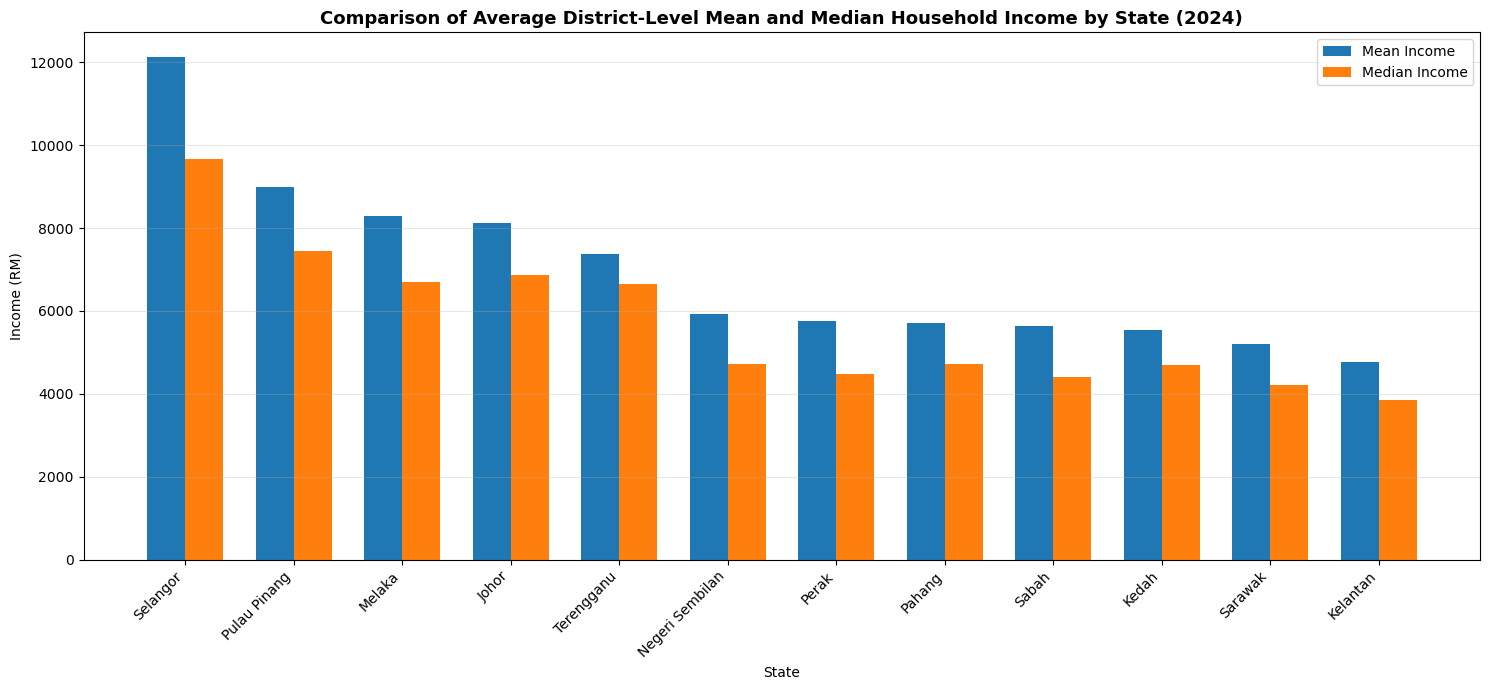

In [68]:
# Set bar positions
x = np.arange(len(income_compare))
width = 0.35

# Create figure
plt.figure(figsize=(15, 7))

# Mean income bars
plt.bar(
    x - width/2,
    income_compare['avg_district_income'],
    width,
    label='Mean Income'
)

# Median income bars
plt.bar(
    x + width/2,
    income_compare['avg_district_median'],
    width,
    label='Median Income'
)

# Chart title and labels
plt.title(
    'Comparison of Average District-Level Mean and Median Household Income by State (2024)',
    fontsize=13,
    fontweight='bold'
)

plt.xlabel('State')
plt.ylabel('Income (RM)')

plt.xticks(
    x,
    income_compare['state'],
    rotation=45,
    ha='right'
)

plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


In [69]:
# Display first 5 records
schools.head()


,state,district,stage,type,date,schools
0,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2017-01-01,7776
1,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2018-01-01,7774
2,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2019-01-01,7773
3,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2020-01-01,7780
4,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2021-01-01,7780


In [70]:
# Check dataset information
schools.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4514 entries, 0 to 4513
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   state     4514 non-null   object
 1   district  4514 non-null   object
 2   stage     4514 non-null   object
 3   type      4514 non-null   object
 4   date      4514 non-null   object
 5   schools   4514 non-null   int64 
dtypes: int64(1), object(5)
memory usage: 211.7+ KB


In [71]:
# Statistical summary
schools.describe(include='all')


,state,district,stage,type,date,schools
count,4514,4514,4514,4514,4514,4514.000000
unique,17,154,3,6,12,NaN
top,Sarawak,All Districts,tertiary,IPTA,2018-01-01,NaN
freq,886,486,1557,1530,504,NaN
mean,NaN,NaN,NaN,NaN,NaN,61.582853
std,NaN,NaN,NaN,NaN,NaN,377.951917
min,NaN,NaN,NaN,NaN,NaN,0.000000
25%,NaN,NaN,NaN,NaN,NaN,0.000000
50%,NaN,NaN,NaN,NaN,NaN,13.000000
75%,NaN,NaN,NaN,NaN,NaN,40.000000


In [72]:
# Display column names
print("Dataset Columns:")
print(schools.columns.tolist())

print("\nDataset Shape:")
print(schools.shape)


Dataset Columns:
['state', 'district', 'stage', 'type', 'date', 'schools']

Dataset Shape:
(4514, 6)


In [73]:
# Check missing values
print("Missing Values:")
print(schools.isnull().sum())


Missing Values:
state       0
district    0
stage       0
type        0
date        0
schools     0
dtype: int64


In [74]:
# Check duplicate records
print(
    "Total Duplicate Records:",
    schools.duplicated().sum()
)


Total Duplicate Records: 0


In [75]:
print("Total States:",
      schools['state'].nunique())

print("\nState List:")
print(sorted(schools['state'].unique()))


Total States: 17

State List:
['Johor', 'Kedah', 'Kelantan', 'Malaysia', 'Melaka', 'Negeri Sembilan', 'Pahang', 'Perak', 'Perlis', 'Pulau Pinang', 'Sabah', 'Sarawak', 'Selangor', 'Terengganu', 'W.P. Kuala Lumpur', 'W.P. Labuan', 'W.P. Putrajaya']


In [76]:
print("Education Stage Categories:")
print(schools['education_stage'].unique())

print("\nRecords by Education Stage:")
print(schools['education_stage'].value_counts())


Education Stage Categories:


KeyError: 'education_stage'

In [77]:
# Display all column names
print("School Dataset Columns:")
print(schools.columns.tolist())


School Dataset Columns:
['state', 'district', 'stage', 'type', 'date', 'schools']


In [78]:
schools.head()

,state,district,stage,type,date,schools
0,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2017-01-01,7776
1,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2018-01-01,7774
2,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2019-01-01,7773
3,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2020-01-01,7780
4,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2021-01-01,7780


In [79]:
for column in schools.columns:
    print(f"\n{column}")
    print(schools[column].unique()[:20])


state
['Malaysia' 'Johor' 'Kedah' 'Kelantan' 'Melaka' 'Negeri Sembilan' 'Pahang'
 'Perak' 'Perlis' 'Pulau Pinang' 'Sabah' 'Sarawak' 'Selangor' 'Terengganu'
 'W.P. Kuala Lumpur' 'W.P. Labuan' 'W.P. Putrajaya']

district
['All Districts' 'Batu Pahat' 'Johor Bahru' 'Kluang' 'Kota Tinggi' 'Kulai'
 'Mersing' 'Muar' 'Pontian' 'Segamat' 'Tangkak' 'Baling' 'Bandar Baharu'
 'Kota Setar' 'Kuala Muda' 'Kubang Pasu' 'Kulim' 'Langkawi' 'Padang Terap'
 'Pendang']

stage
['primary' 'secondary' 'tertiary']

type
['Sekolah Rendah Kerajaan' 'Sekolah Menengah Kerajaan' 'IPTA'
 'Institut Pendidikan Guru' 'Politeknik' 'Kolej Komuniti']

date
['2017-01-01' '2018-01-01' '2019-01-01' '2020-01-01' '2021-01-01'
 '2022-01-01' '2023-06-30' '2024-06-30' '2025-06-30' '2023-01-01'
 '2024-01-01' '2025-01-01']

schools
[7776 7774 7773 7780 7778 7779 2416 2433 2439 2440 2444 2452 2457 2460
   20   27   36   94   99  101]


In [80]:
# Check education stage categories
print("Education Stage Categories:")
print(schools['stage'].unique())

print("\nRecords by Education Stage:")
print(schools['stage'].value_counts())


Education Stage Categories:
['primary' 'secondary' 'tertiary']

Records by Education Stage:
stage
tertiary     1557
primary      1489
secondary    1468
Name: count, dtype: int64


In [81]:
# Count records by state
print("Total States:")
print(schools['state'].nunique())

print("\nRecords by State:")
print(schools['state'].value_counts())


Total States:
17

Records by State:
state
Sarawak              886
Sabah                720
Perak                354
Kedah                343
Pahang               333
Kelantan             314
Johor                297
Selangor             270
Terengganu           243
Negeri Sembilan      214
Pulau Pinang         162
Melaka               108
Malaysia              54
Perlis                54
W.P. Kuala Lumpur     54
W.P. Labuan           54
W.P. Putrajaya        54
Name: count, dtype: int64


In [82]:
# Check education stages by state
stage_by_state = pd.crosstab(
    schools['state'],
    schools['stage']
)

display(stage_by_state)


stage,primary,secondary,tertiary
state,,,
Johor,99,99,99
Kedah,113,113,117
Kelantan,107,99,108
Malaysia,9,9,36
Melaka,36,36,36
Negeri Sembilan,71,71,72
Pahang,108,108,117
Perak,114,114,126
Perlis,18,18,18


In [83]:
# Check available dates
print("Available Dates:")
print(sorted(schools['date'].unique()))

print("\nRecords by Date:")
print(schools['date'].value_counts().sort_index())


Available Dates:
['2017-01-01', '2018-01-01', '2019-01-01', '2020-01-01', '2021-01-01', '2022-01-01', '2023-01-01', '2023-06-30', '2024-01-01', '2024-06-30', '2025-01-01', '2025-06-30']

Records by Date:
date
2017-01-01    479
2018-01-01    504
2019-01-01    504
2020-01-01    504
2021-01-01    504
2022-01-01    504
2023-01-01    173
2023-06-30    332
2024-01-01    173
2024-06-30    332
2025-01-01    173
2025-06-30    332
Name: count, dtype: int64


In [84]:
# Check district categories
print("Total District Categories:",
      schools['district'].nunique())

print("\nDistrict Categories:")
print(schools['district'].value_counts().head(20))

# Check All Districts records
print("\nAll Districts Records:")
display(
    schools[schools['district'] == 'All Districts'].head(10)
)


Total District Categories: 154

District Categories:
district
All Districts    486
Batu Pahat        27
Johor Bahru       27
Kluang            27
Kota Tinggi       27
Kulai             27
Mersing           27
Muar              27
Pontian           27
Segamat           27
Tangkak           27
Baling            27
Bandar Baharu     27
Kota Setar        27
Kuala Muda        27
Kubang Pasu       27
Langkawi          27
Padang Terap      27
Jeli              27
Pendang           27
Name: count, dtype: int64

All Districts Records:


,state,district,stage,type,date,schools
0,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2017-01-01,7776
1,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2018-01-01,7774
2,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2019-01-01,7773
3,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2020-01-01,7780
4,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2021-01-01,7780
5,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2022-01-01,7778
6,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2023-06-30,7779
7,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2024-06-30,7776
8,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2025-06-30,7778
9,Malaysia,All Districts,secondary,Sekolah Menengah Kerajaan,2017-01-01,2416


In [85]:
# Check schools column
print("Schools Data Type:")
print(schools['schools'].dtype)

print("\nSchools Statistical Summary:")
print(schools['schools'].describe())


Schools Data Type:
int64

Schools Statistical Summary:
count    4514.000000
mean       61.582853
std       377.951917
min         0.000000
25%         0.000000
50%        13.000000
75%        40.000000
max      7780.000000
Name: schools, dtype: float64


In [86]:
# Check available years
print("Available Dates:")
print(sorted(schools['date'].unique()))

# Check district categories
print("\nDistrict Categories:")
print(schools['district'].value_counts().head(20))

# Check All Districts records
print("\nAll Districts Records:")
display(
    schools[
        schools['district'] == 'All Districts'
    ].head(10)
)


Available Dates:
['2017-01-01', '2018-01-01', '2019-01-01', '2020-01-01', '2021-01-01', '2022-01-01', '2023-01-01', '2023-06-30', '2024-01-01', '2024-06-30', '2025-01-01', '2025-06-30']

District Categories:
district
All Districts    486
Batu Pahat        27
Johor Bahru       27
Kluang            27
Kota Tinggi       27
Kulai             27
Mersing           27
Muar              27
Pontian           27
Segamat           27
Tangkak           27
Baling            27
Bandar Baharu     27
Kota Setar        27
Kuala Muda        27
Kubang Pasu       27
Langkawi          27
Padang Terap      27
Jeli              27
Pendang           27
Name: count, dtype: int64

All Districts Records:


,state,district,stage,type,date,schools
0,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2017-01-01,7776
1,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2018-01-01,7774
2,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2019-01-01,7773
3,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2020-01-01,7780
4,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2021-01-01,7780
5,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2022-01-01,7778
6,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2023-06-30,7779
7,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2024-06-30,7776
8,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2025-06-30,7778
9,Malaysia,All Districts,secondary,Sekolah Menengah Kerajaan,2017-01-01,2416


In [87]:
# Convert date column to datetime
schools['date'] = pd.to_datetime(schools['date'])

# Count records by year
print("Records by Year:")
print(
    schools.groupby(
        schools['date'].dt.year
    ).size()
)

print("\nRecords by Exact Date:")
print(schools['date'].value_counts().sort_index())


Records by Year:
date
2017    479
2018    504
2019    504
2020    504
2021    504
2022    504
2023    505
2024    505
2025    505
dtype: int64

Records by Exact Date:
date
2017-01-01    479
2018-01-01    504
2019-01-01    504
2020-01-01    504
2021-01-01    504
2022-01-01    504
2023-01-01    173
2023-06-30    332
2024-01-01    173
2024-06-30    332
2025-01-01    173
2025-06-30    332
Name: count, dtype: int64


In [88]:
# Check school types by education stage
stage_type = pd.crosstab(
    schools['stage'],
    schools['type']
)

display(stage_type)


type,IPTA,Institut Pendidikan Guru,Kolej Komuniti,Politeknik,Sekolah Menengah Kerajaan,Sekolah Rendah Kerajaan
stage,,,,,,
primary,0,0,0,0,0,1489
secondary,0,0,0,0,1468,0
tertiary,1530,9,9,9,0,0


In [89]:
# Exclude national aggregate records temporarily
district_data = schools[
    (schools['district'] != 'All Districts') &
    (schools['state'] != 'Malaysia')
].copy()

print("District-Level Dataset Shape:")
print(district_data.shape)

print("\nSample District-Level Records:")
display(district_data.head(10))


District-Level Dataset Shape:
(4028, 6)

Sample District-Level Records:


,state,district,stage,type,date,schools
81,Johor,Batu Pahat,primary,Sekolah Rendah Kerajaan,2017-01-01,144
82,Johor,Batu Pahat,primary,Sekolah Rendah Kerajaan,2018-01-01,144
83,Johor,Batu Pahat,primary,Sekolah Rendah Kerajaan,2019-01-01,144
84,Johor,Batu Pahat,primary,Sekolah Rendah Kerajaan,2020-01-01,144
85,Johor,Batu Pahat,primary,Sekolah Rendah Kerajaan,2021-01-01,144
86,Johor,Batu Pahat,primary,Sekolah Rendah Kerajaan,2022-01-01,144
87,Johor,Batu Pahat,primary,Sekolah Rendah Kerajaan,2023-06-30,144
88,Johor,Batu Pahat,primary,Sekolah Rendah Kerajaan,2024-06-30,144
89,Johor,Batu Pahat,primary,Sekolah Rendah Kerajaan,2025-06-30,144
90,Johor,Batu Pahat,secondary,Sekolah Menengah Kerajaan,2017-01-01,32


In [90]:
# Check duplicate combinations
duplicate_check = district_data.duplicated(
    subset=[
        'state',
        'district',
        'stage',
        'date'
    ]
).sum()

print("Duplicate District-Stage-Date Records:",
      duplicate_check)


Duplicate District-Stage-Date Records: 0


In [91]:
# Check number of states available for each date
state_coverage = (
    district_data.groupby('date')['state']
    .nunique()
)

print("State Coverage by Date:")
print(state_coverage)


State Coverage by Date:
date
2017-01-01    16
2018-01-01    16
2019-01-01    16
2020-01-01    16
2021-01-01    16
2022-01-01    16
2023-01-01    16
2023-06-30    16
2024-01-01    16
2024-06-30    16
2025-01-01    16
2025-06-30    16
Name: state, dtype: int64


In [92]:
# Check education stage coverage by date
stage_coverage = (
    district_data.groupby('date')['stage']
    .nunique()
)

print("Education Stage Coverage by Date:")
print(stage_coverage)


Education Stage Coverage by Date:
date
2017-01-01    3
2018-01-01    3
2019-01-01    3
2020-01-01    3
2021-01-01    3
2022-01-01    3
2023-01-01    1
2023-06-30    2
2024-01-01    1
2024-06-30    2
2025-01-01    1
2025-06-30    2
Name: stage, dtype: int64


In [93]:
print("School Types:")
print(district_data['type'].value_counts())

print("\nEducation Stages:")
print(district_data['stage'].value_counts())


School Types:
type
IPTA                         1377
Sekolah Rendah Kerajaan      1336
Sekolah Menengah Kerajaan    1315
Name: count, dtype: int64

Education Stages:
stage
tertiary     1377
primary      1336
secondary    1315
Name: count, dtype: int64


In [94]:
state_coverage = (
    district_data.groupby('date')['state']
    .nunique()
)

print("State Coverage by Date:")
print(state_coverage)

State Coverage by Date:
date
2017-01-01    16
2018-01-01    16
2019-01-01    16
2020-01-01    16
2021-01-01    16
2022-01-01    16
2023-01-01    16
2023-06-30    16
2024-01-01    16
2024-06-30    16
2025-01-01    16
2025-06-30    16
Name: state, dtype: int64


In [95]:
stage_coverage = (
    district_data.groupby('date')['stage']
    .nunique()
)

print("Education Stage Coverage by Date:")
print(stage_coverage)

Education Stage Coverage by Date:
date
2017-01-01    3
2018-01-01    3
2019-01-01    3
2020-01-01    3
2021-01-01    3
2022-01-01    3
2023-01-01    1
2023-06-30    2
2024-01-01    1
2024-06-30    2
2025-01-01    1
2025-06-30    2
Name: stage, dtype: int64


In [96]:
stage_by_date = pd.crosstab(
    district_data['date'],
    district_data['stage']
)

print("Education Stage Distribution by Date:")
display(stage_by_date)

Education Stage Distribution by Date:


stage,primary,secondary,tertiary
date,,,
2017-01-01,136,136,153
2018-01-01,150,147,153
2019-01-01,150,147,153
2020-01-01,150,147,153
2021-01-01,150,147,153
2022-01-01,150,147,153
2023-01-01,0,0,153
2023-06-30,150,148,0
2024-01-01,0,0,153


In [97]:
# Filter complete years (2018-2022)
education_trend = district_data[
    district_data['date'].isin([
        '2018-01-01',
        '2019-01-01',
        '2020-01-01',
        '2021-01-01',
        '2022-01-01'
    ])
].copy()

# Calculate total schools by year and education stage
education_summary = (
    education_trend
    .groupby(['date', 'stage'])['schools']
    .sum()
    .reset_index()
)

# Display results
print("Education Trend Dataset:")
display(education_summary)

print("\nDataset Shape:", education_summary.shape)

Education Trend Dataset:


C:\Users\asus\AppData\Local\Temp\ipykernel_8828\91201484.py:3: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  district_data['date'].isin([


,date,stage,schools
0,2018-01-01,primary,7774
1,2018-01-01,secondary,2433
2,2018-01-01,tertiary,20
3,2019-01-01,primary,7773
4,2019-01-01,secondary,2439
5,2019-01-01,tertiary,20
6,2020-01-01,primary,7780
7,2020-01-01,secondary,2440
8,2020-01-01,tertiary,20
9,2021-01-01,primary,7780



Dataset Shape: (15, 3)


In [98]:
# Filter complete years (2018-2022)
education_trend = district_data[
    district_data['date'].dt.year.between(2018, 2022)
].copy()

# Calculate total schools by year and education stage
education_summary = (
    education_trend
    .groupby(['date', 'stage'])['schools']
    .sum()
    .reset_index()
)

# Display results
print("Education Trend Dataset:")
display(education_summary)

print("\nDataset Shape:", education_summary.shape)

print("\nMissing Values:")
print(education_summary.isnull().sum())

Education Trend Dataset:


,date,stage,schools
0,2018-01-01,primary,7774
1,2018-01-01,secondary,2433
2,2018-01-01,tertiary,20
3,2019-01-01,primary,7773
4,2019-01-01,secondary,2439
5,2019-01-01,tertiary,20
6,2020-01-01,primary,7780
7,2020-01-01,secondary,2440
8,2020-01-01,tertiary,20
9,2021-01-01,primary,7780



Dataset Shape: (15, 3)

Missing Values:
date       0
stage      0
schools    0
dtype: int64


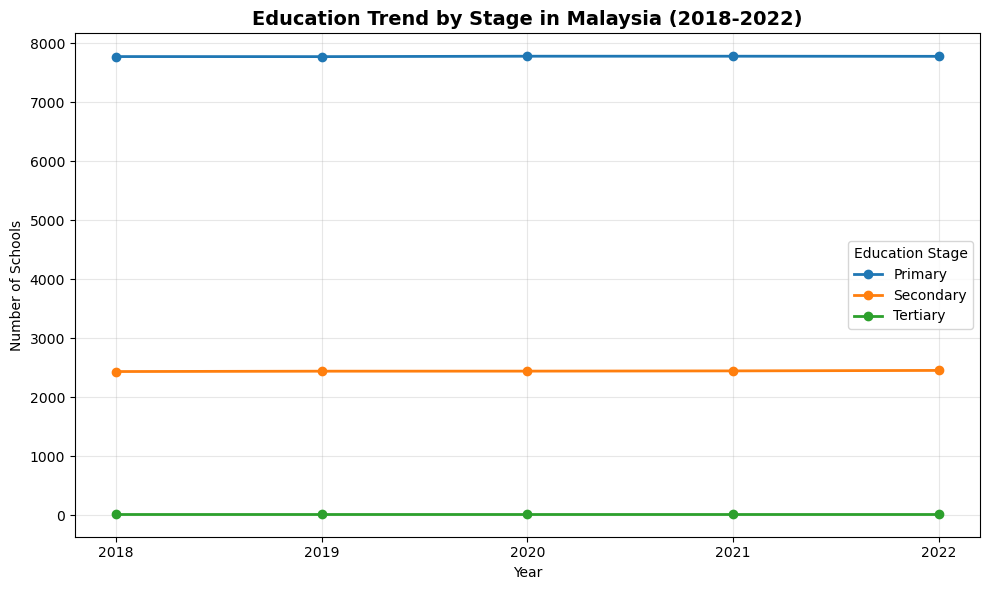

In [99]:
import matplotlib.pyplot as plt

# Pivot dataset for visualization
education_pivot = education_summary.pivot(
    index='date',
    columns='stage',
    values='schools'
)

# Plot line chart
plt.figure(figsize=(10, 6))

for stage in education_pivot.columns:
    plt.plot(
        education_pivot.index.year,
        education_pivot[stage],
        marker='o',
        linewidth=2,
        label=stage.capitalize()
    )

plt.title(
    'Education Trend by Stage in Malaysia (2018-2022)',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Year')
plt.ylabel('Number of Schools')
plt.xticks(education_pivot.index.year)
plt.legend(title='Education Stage')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

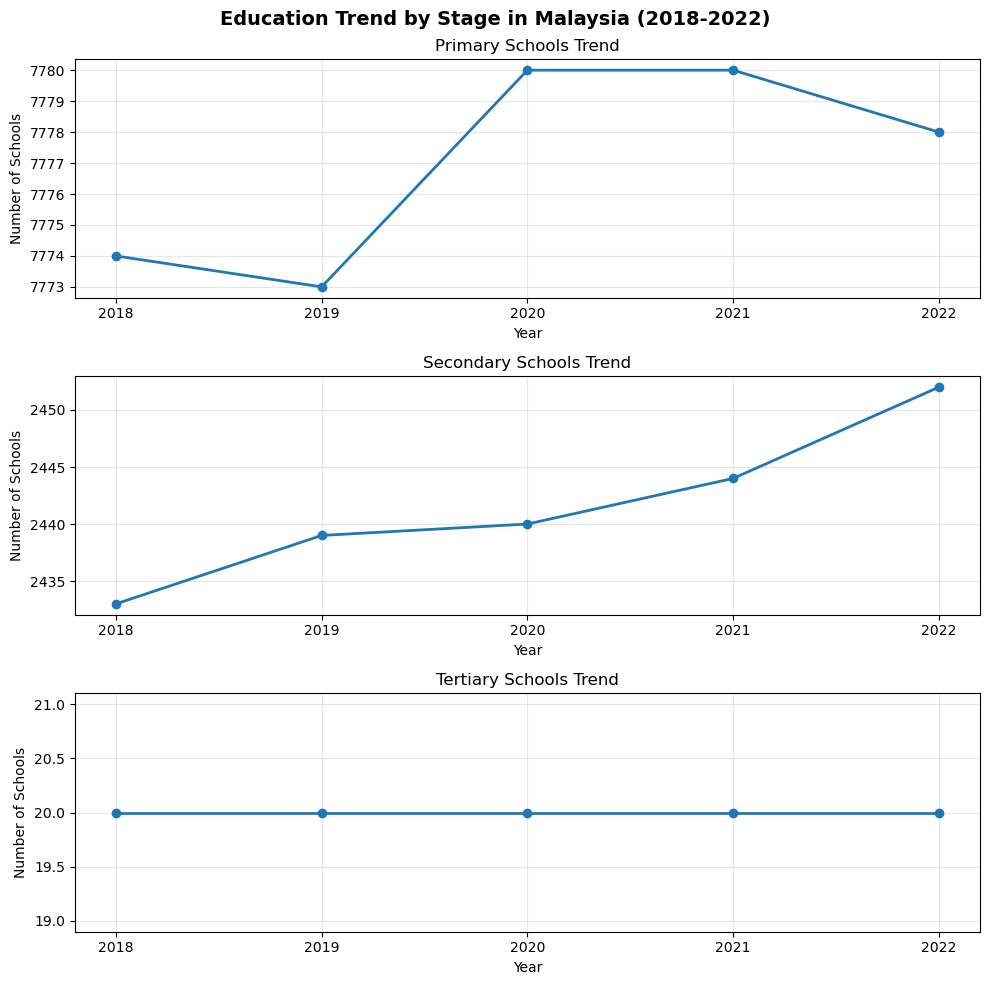

In [100]:
# Create separate plots for each education stage
fig, axes = plt.subplots(3, 1, figsize=(10, 10))

stages = ['primary', 'secondary', 'tertiary']

for ax, stage in zip(axes, stages):

    ax.plot(
        education_pivot.index.year,
        education_pivot[stage],
        marker='o',
        linewidth=2
    )

    ax.set_title(f'{stage.capitalize()} Schools Trend')
    ax.set_xlabel('Year')
    ax.set_ylabel('Number of Schools')
    ax.set_xticks(education_pivot.index.year)
    ax.grid(True, alpha=0.3)

plt.suptitle(
    'Education Trend by Stage in Malaysia (2018-2022)',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

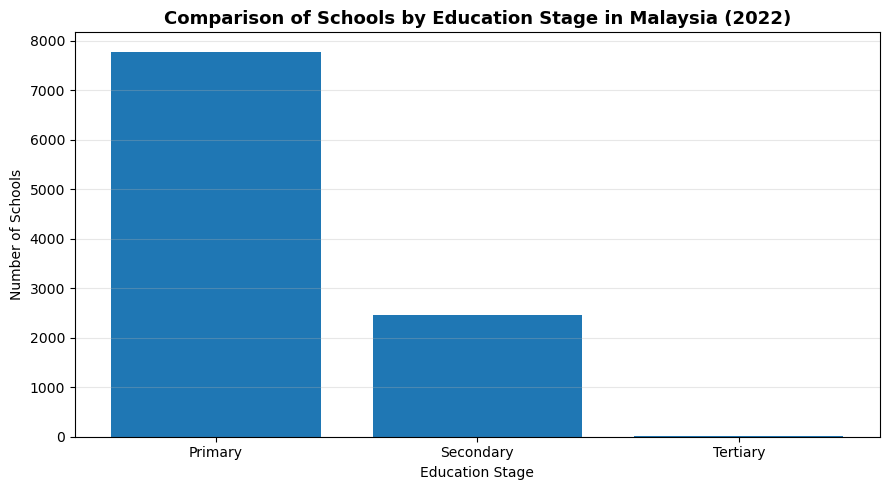

Education Stage Comparison (2022):


,date,stage,schools
12,2022-01-01,primary,7778
13,2022-01-01,secondary,2452
14,2022-01-01,tertiary,20


In [101]:
# Filter education data for 2022
education_2022 = education_summary[
    education_summary['date'].dt.year == 2022
]

# Create bar chart
plt.figure(figsize=(9, 5))

plt.bar(
    education_2022['stage'].str.capitalize(),
    education_2022['schools']
)

plt.title(
    'Comparison of Schools by Education Stage in Malaysia (2022)',
    fontsize=13,
    fontweight='bold'
)

plt.xlabel('Education Stage')
plt.ylabel('Number of Schools')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Display values
print("Education Stage Comparison (2022):")
display(education_2022)

In [102]:
# Calculate percentage distribution
education_2022 = education_2022.copy()

total_schools = education_2022['schools'].sum()

education_2022['percentage'] = (
    education_2022['schools'] / total_schools
) * 100

print("Total Schools:", total_schools)

print("\nPercentage Distribution:")
display(education_2022)

Total Schools: 10250

Percentage Distribution:


,date,stage,schools,percentage
12,2022-01-01,primary,7778,75.882927
13,2022-01-01,secondary,2452,23.921951
14,2022-01-01,tertiary,20,0.195122


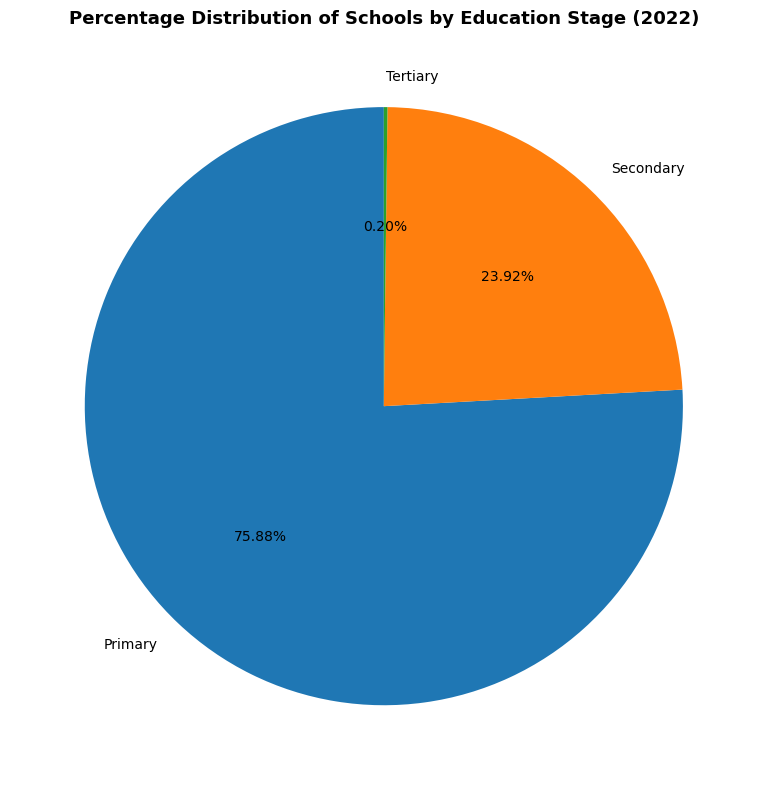

In [103]:
# Create pie chart
plt.figure(figsize=(8, 8))

plt.pie(
    education_2022['schools'],
    labels=education_2022['stage'].str.capitalize(),
    autopct='%1.2f%%',
    startangle=90
)

plt.title(
    'Percentage Distribution of Schools by Education Stage (2022)',
    fontsize=13,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

In [104]:
# Calculate yearly growth
education_growth = education_summary.pivot(
    index='date',
    columns='stage',
    values='schools'
)

# Calculate absolute changes
growth_change = education_growth.diff()

print("Yearly Changes in Number of Schools:")
display(growth_change)

# Calculate percentage growth
growth_percentage = education_growth.pct_change() * 100

print("\nYearly Percentage Growth:")
display(growth_percentage)

Yearly Changes in Number of Schools:


stage,primary,secondary,tertiary
date,,,
2018-01-01,NaN,NaN,NaN
2019-01-01,-1.0,6.0,0.0
2020-01-01,7.0,1.0,0.0
2021-01-01,0.0,4.0,0.0
2022-01-01,-2.0,8.0,0.0



Yearly Percentage Growth:


stage,primary,secondary,tertiary
date,,,
2018-01-01,NaN,NaN,NaN
2019-01-01,-0.012863,0.246609,0.0
2020-01-01,0.090055,0.041000,0.0
2021-01-01,0.000000,0.163934,0.0
2022-01-01,-0.025707,0.327332,0.0


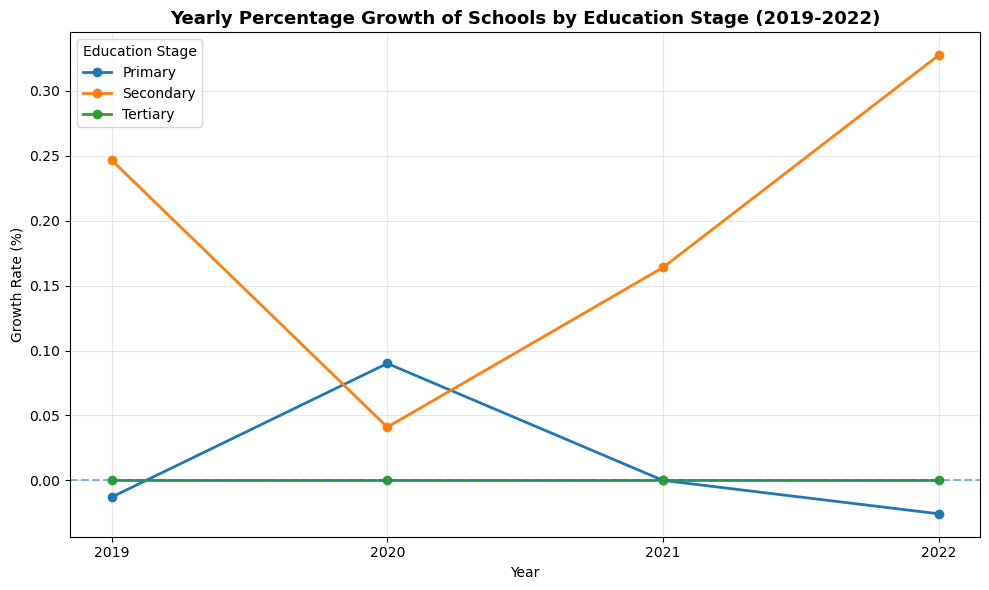

In [105]:
# Remove first year (NaN values)
growth_plot = growth_percentage.dropna()

# Create visualization
plt.figure(figsize=(10, 6))

for stage in growth_plot.columns:
    plt.plot(
        growth_plot.index.year,
        growth_plot[stage],
        marker='o',
        linewidth=2,
        label=stage.capitalize()
    )

plt.title(
    'Yearly Percentage Growth of Schools by Education Stage (2019-2022)',
    fontsize=13,
    fontweight='bold'
)

plt.xlabel('Year')
plt.ylabel('Growth Rate (%)')
plt.xticks(growth_plot.index.year)
plt.axhline(y=0, linestyle='--', alpha=0.5)
plt.legend(title='Education Stage')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [106]:
# Calculate overall growth (2018-2022)

overall_growth = pd.DataFrame({
    '2018': education_pivot.iloc[0],
    '2022': education_pivot.iloc[-1]
})

overall_growth['total_change'] = (
    overall_growth['2022'] - overall_growth['2018']
)

overall_growth['growth_percentage'] = (
    overall_growth['total_change'] /
    overall_growth['2018']
) * 100

print("Overall Education Growth (2018-2022):")
display(overall_growth.round(3))

Overall Education Growth (2018-2022):


,2018,2022,total_change,growth_percentage
stage,,,,
primary,7774,7778,4,0.051
secondary,2433,2452,19,0.781
tertiary,20,20,0,0.000


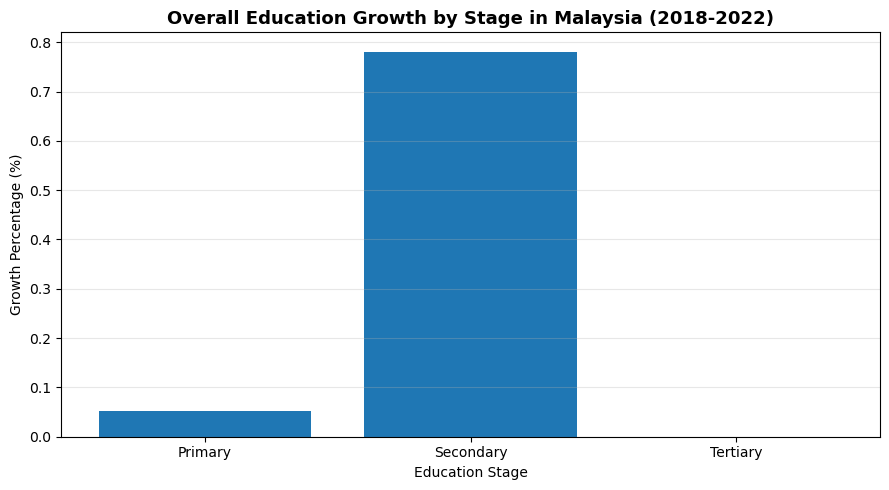

In [107]:
# Create overall growth visualization
plt.figure(figsize=(9, 5))

plt.bar(
    overall_growth.index.str.capitalize(),
    overall_growth['growth_percentage']
)

plt.title(
    'Overall Education Growth by Stage in Malaysia (2018-2022)',
    fontsize=13,
    fontweight='bold'
)

plt.xlabel('Education Stage')
plt.ylabel('Growth Percentage (%)')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [108]:
# Create education growth ranking
growth_ranking = overall_growth.copy()

growth_ranking['rank'] = (
    growth_ranking['growth_percentage']
    .rank(ascending=False, method='min')
    .astype(int)
)

growth_ranking = growth_ranking.sort_values(
    by='growth_percentage',
    ascending=False
)

print("Education Growth Ranking (2018-2022):")

display(
    growth_ranking[
        ['2018', '2022', 'total_change',
         'growth_percentage', 'rank']
    ].round(3)
)

print("\nHighest Growth Stage:")
print(growth_ranking.index[0].capitalize())

print("\nLowest Growth Stage:")
print(growth_ranking.index[-1].capitalize())

Education Growth Ranking (2018-2022):


,2018,2022,total_change,growth_percentage,rank
stage,,,,,
secondary,2433,2452,19,0.781,1
primary,7774,7778,4,0.051,2
tertiary,20,20,0,0.000,3



Highest Growth Stage:
Secondary

Lowest Growth Stage:
Tertiary


In [109]:
# Filter education data for 2022
state_education_2022 = district_data[
    district_data['date'].dt.year == 2022
].copy()

# Calculate total schools by state and education stage
state_stage_summary = (
    state_education_2022
    .groupby(['state', 'stage'])['schools']
    .sum()
    .reset_index()
)

# Create pivot table
state_stage_pivot = state_stage_summary.pivot(
    index='state',
    columns='stage',
    values='schools'
).fillna(0)

print("Education Distribution by State (2022):")
display(state_stage_pivot)

print("\nDataset Shape:", state_stage_pivot.shape)

Education Distribution by State (2022):


stage,primary,secondary,tertiary
state,,,
Johor,908,284,2
Kedah,548,204,1
Kelantan,418,178,1
Melaka,238,78,1
Negeri Sembilan,353,126,1
Pahang,543,198,1
Perak,852,253,1
Perlis,74,30,1
Pulau Pinang,270,128,1



Dataset Shape: (16, 3)


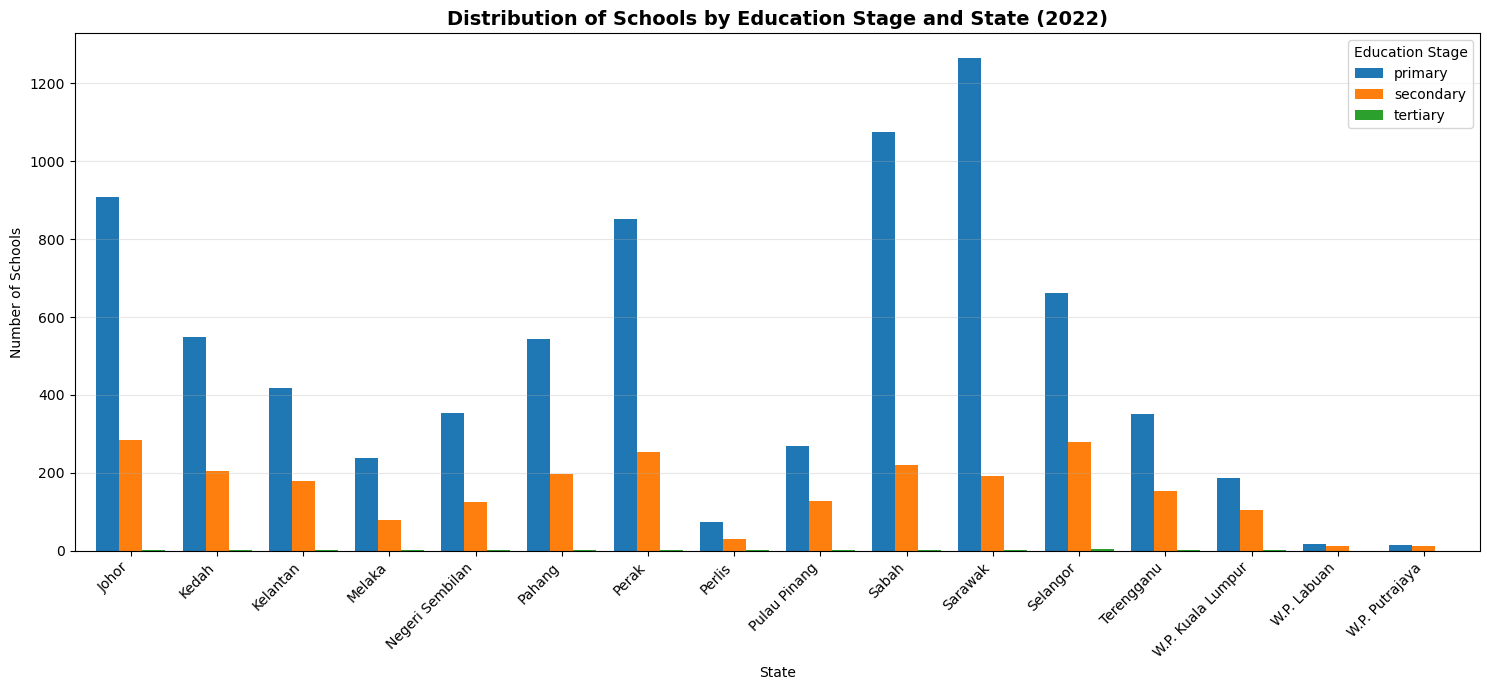

In [110]:
import matplotlib.pyplot as plt

# Create grouped bar chart
state_stage_pivot.plot(
    kind='bar',
    figsize=(15, 7),
    width=0.8
)

plt.title(
    'Distribution of Schools by Education Stage and State (2022)',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('State')
plt.ylabel('Number of Schools')

plt.xticks(rotation=45, ha='right')
plt.legend(title='Education Stage')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [111]:
# Find highest and lowest school distribution

for stage in state_stage_pivot.columns:

    highest_state = state_stage_pivot[stage].idxmax()
    lowest_state = state_stage_pivot[stage].idxmin()

    print(f"\nEducation Stage: {stage.title()}")

    print(
        "Highest:",
        highest_state,
        "-",
        state_stage_pivot.loc[highest_state, stage]
    )

    print(
        "Lowest:",
        lowest_state,
        "-",
        state_stage_pivot.loc[lowest_state, stage]
    )


Education Stage: Primary
Highest: Sarawak - 1265
Lowest: W.P. Putrajaya - 16

Education Stage: Secondary
Highest: Johor - 284
Lowest: W.P. Labuan - 11

Education Stage: Tertiary
Highest: Selangor - 4
Lowest: W.P. Labuan - 0


In [112]:
# Calculate total schools by state

state_stage_pivot['total_schools'] = (
    state_stage_pivot.sum(axis=1)
)

# Sort states by total schools
state_total = state_stage_pivot.sort_values(
    by='total_schools',
    ascending=False
)

print("Total Schools by State (2022):")
display(state_total)

print("\nHighest Total Schools:")
print(state_total['total_schools'].idxmax())

print("\nLowest Total Schools:")
print(state_total['total_schools'].idxmin())

Total Schools by State (2022):


stage,primary,secondary,tertiary,total_schools
state,,,,
Sarawak,1265,193,1,1459
Sabah,1075,221,1,1297
Johor,908,284,2,1194
Perak,852,253,1,1106
Selangor,661,279,4,944
Kedah,548,204,1,753
Pahang,543,198,1,742
Kelantan,418,178,1,597
Terengganu,352,154,2,508



Highest Total Schools:
Sarawak

Lowest Total Schools:
W.P. Putrajaya


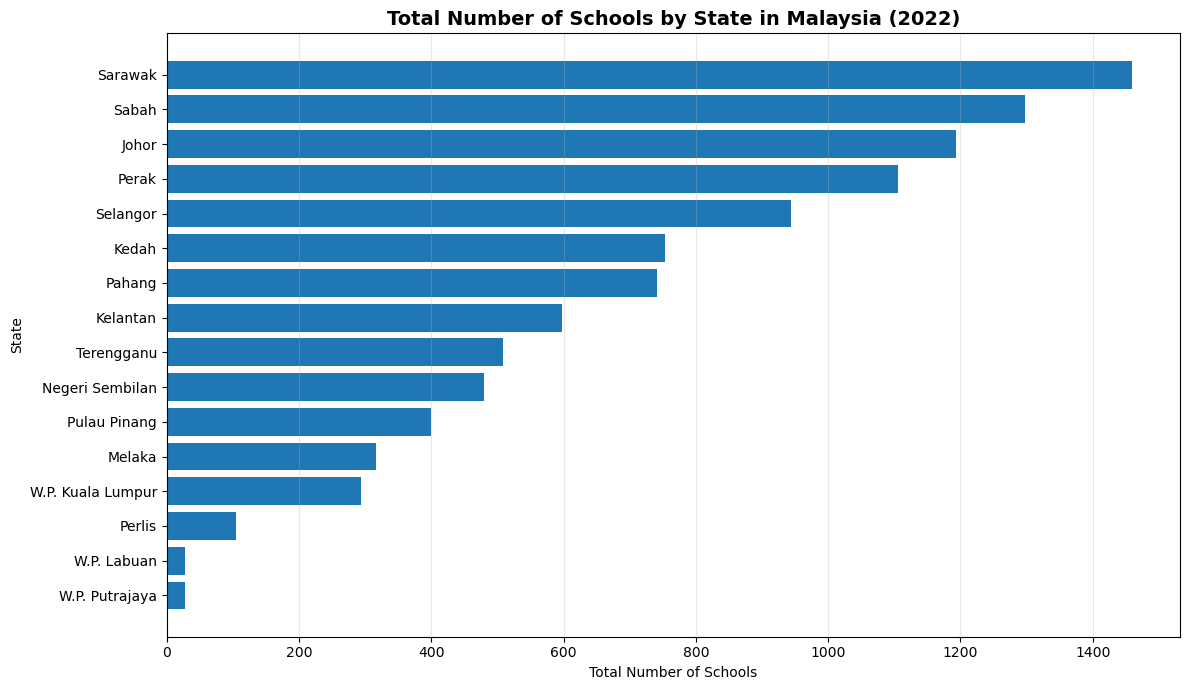

In [113]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

plt.barh(
    state_total.index,
    state_total['total_schools']
)

plt.title(
    'Total Number of Schools by State in Malaysia (2022)',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Total Number of Schools')
plt.ylabel('State')

plt.gca().invert_yaxis()

plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [114]:
# Calculate percentage distribution by state

state_total = state_total.copy()

total_all_schools = state_total['total_schools'].sum()

state_total['percentage'] = (
    state_total['total_schools'] / total_all_schools
) * 100

print("Total Schools in Malaysia:", total_all_schools)

print("\nPercentage Distribution by State:")

display(
    state_total[
        ['total_schools', 'percentage']
    ].round(2)
)

Total Schools in Malaysia: 10250

Percentage Distribution by State:


stage,total_schools,percentage
state,,
Sarawak,1459,14.23
Sabah,1297,12.65
Johor,1194,11.65
Perak,1106,10.79
Selangor,944,9.21
Kedah,753,7.35
Pahang,742,7.24
Kelantan,597,5.82
Terengganu,508,4.96


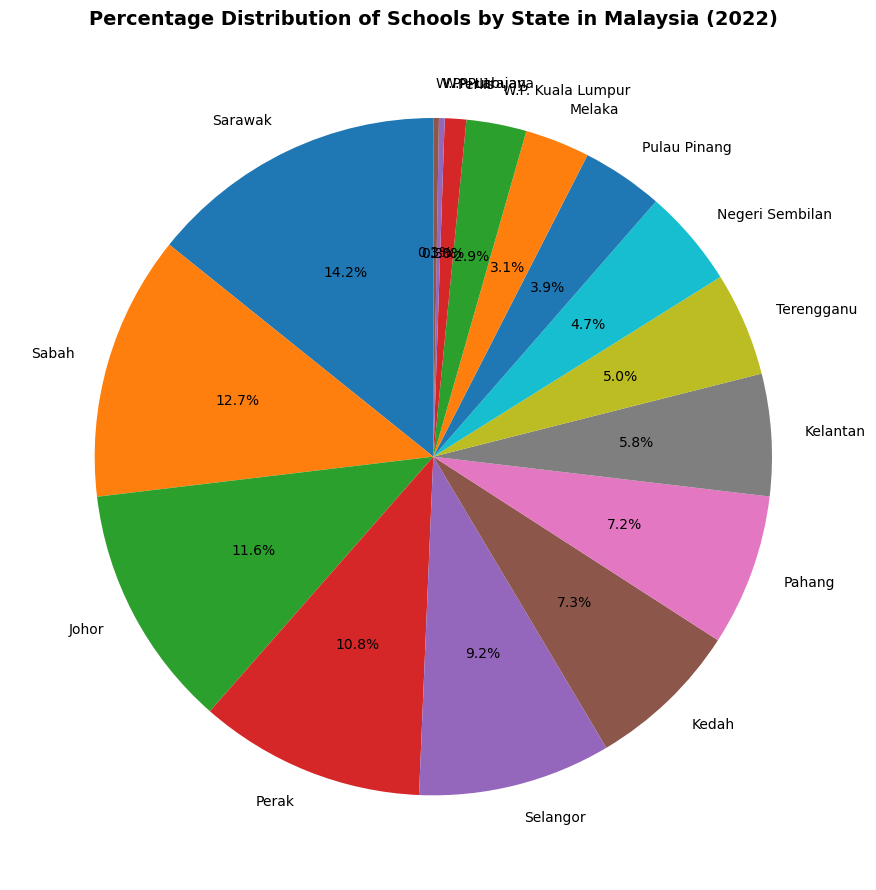

In [115]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 9))

plt.pie(
    state_total['percentage'],
    labels=state_total.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title(
    'Percentage Distribution of Schools by State in Malaysia (2022)',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

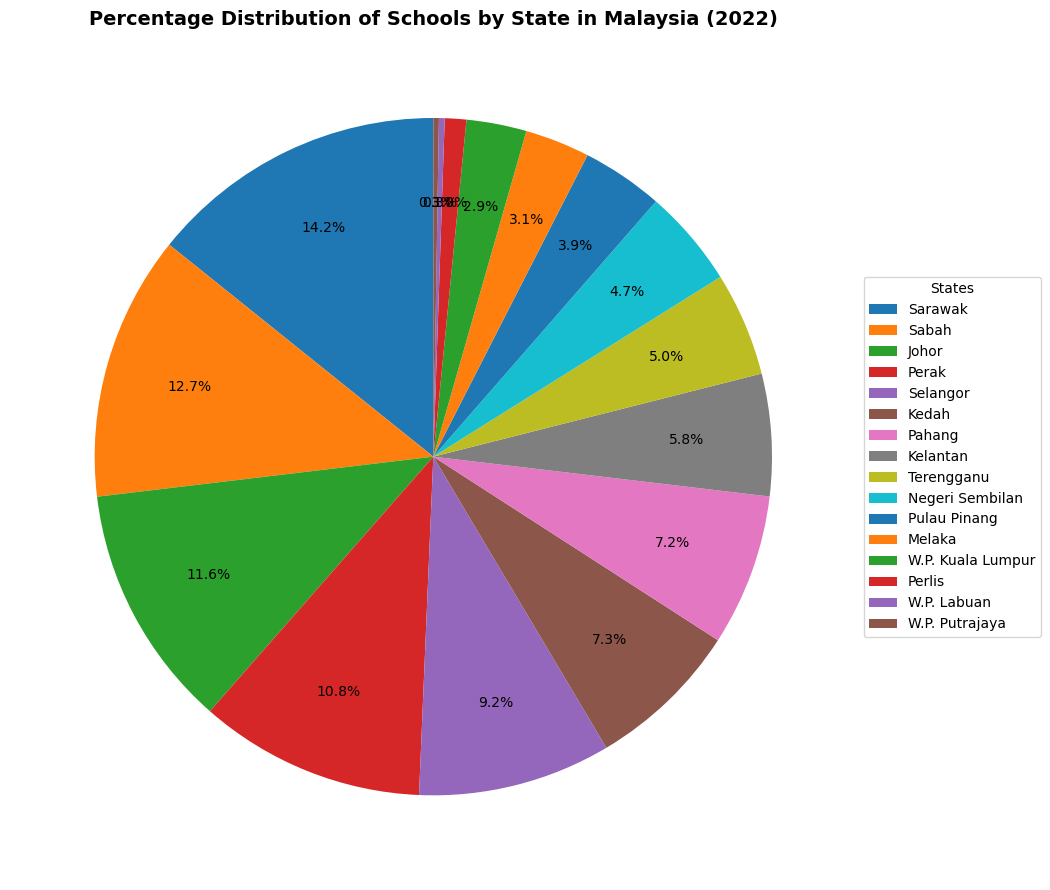

In [116]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 9))

wedges, texts, autotexts = plt.pie(
    state_total['percentage'],
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.75
)

plt.legend(
    wedges,
    state_total.index,
    title="States",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.title(
    'Percentage Distribution of Schools by State in Malaysia (2022)',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

In [117]:
# Identify highest and lowest percentage

highest_percentage = state_total['percentage'].idxmax()
lowest_percentage = state_total['percentage'].idxmin()

print("Highest Percentage Distribution:")
print("State:", highest_percentage)
print("Percentage:",
      round(state_total.loc[highest_percentage, 'percentage'], 2), "%")

print("\nLowest Percentage Distribution:")
print("State:", lowest_percentage)
print("Percentage:",
      round(state_total.loc[lowest_percentage, 'percentage'], 2), "%")

Highest Percentage Distribution:
State: Sarawak
Percentage: 14.23 %

Lowest Percentage Distribution:
State: W.P. Putrajaya
Percentage: 0.26 %


In [118]:
# Final validation for education dataset

print("Final Dataset Validation")

print("\nDataset Shape:")
print(state_total.shape)

print("\nMissing Values:")
print(state_total.isnull().sum())

print("\nDuplicate Records:")
print(state_total.duplicated().sum())

print("\nTotal Schools:")
print(state_total['total_schools'].sum())

print("\nTotal Percentage:")
print(round(state_total['percentage'].sum(), 2), "%")

Final Dataset Validation

Dataset Shape:
(16, 5)

Missing Values:
stage
primary          0
secondary        0
tertiary         0
total_schools    0
percentage       0
dtype: int64

Duplicate Records:
0

Total Schools:
10250

Total Percentage:
100.0 %
